# ORCA-Pack — PiggyBack Hybrid — Order Robustness

Final ORCA-Pack hybrid configuration (`a0.7_floor`: smart-pruning mix a = 0.7, fair share `floor`, learned binary reuse masks over earlier-owned weights, external LDA task-ID router) re-run on the task orders of `task_order.json`.

* Nothing is re-selected per order: the configuration, the seed (67), `MASK_LR` and the router (`FROZEN_ROUTER`) are fixed. Only `ORDER_ID` changes.
* Every order is a full 10-task run (about 25 min on a T4) plus the `ext_lda` router only (about 3 min).
* Results are written to `RESULTS_JSON` after each order, a restarted session resumes where it stopped.
* The cells are the cells of `ORCA-Pack_PiggyHybrid.ipynb` (unchanged, except the data cell which gets `set_order`). The router study keeps only `C: ext_lda`; soft fusion is not run (it is reported only in the original notebook).

In [1]:
import warnings
warnings.filterwarnings("ignore")

import os, math, time, json, random, gc, socket, urllib.error
from pathlib import Path
from copy import deepcopy
from collections import defaultdict
from contextlib import contextmanager

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
import torchvision.models as tvm
import torchvision.transforms as T

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
USE_AMP = DEVICE.type == "cuda"
T_START = time.time()
print("Device :", DEVICE)

Device : cuda


In [2]:
# Configurations

SEED = 67
N_TASKS = 10
CLASSES_PER_TASK = 10
ORDER_ID = 0
IMAGE_SIZE = 32
BATCH_SIZE = 128
NUM_WORKERS = 2
PRETRAINED = True
IMAGENET_WEIGHTS_PATH = None
ALLOW_RANDOM_INIT = False
GN_GROUPS = 32

EPOCHS_PER_TASK = 30
RETRAIN_EPOCHS = 8
RETRAIN_LR_SCALE = 0.3
CONV_LR = 1e-4
CONV_WD = 0.0
AUX_LR = 1e-3

# Progressive Capacity allocation
USE_PILOT = True
FIXED_PRUNE = 0.5
PRUNE_GRID = (0.5, 0.7, 0.8, 0.9, 0.95, 0.98, 0.99)
PRUNE_GRID_T1_EXTRA = (0.4,)
PILOT_EPOCHS = 4
PILOT_TOL = 0.02
PILOT_REF = "tail"
PILOT_SMOOTH = True
PILOT_DIAG_ONE = True

# Fair Share
ALLOC_MODE = "floor" 
CAP_X = 3
FS_SLACK = {2: 2.0, 3: 2.0}
FS_DEFAULT_SLACK = 1.0
FLOOR_GAMMA = 1.0
MAX_KEEP_T1 = 0.6

# Smart Pruning 
SCORE_A = 0.7
TASK_GN = True
FREE_INIT = "keep"
CFG_KEYS = ("SCORE_A", "ALLOC_MODE", "CAP_X", "FS_SLACK", "FS_DEFAULT_SLACK", "FLOOR_GAMMA", "MAX_KEEP_T1", "USE_PILOT",
            "FIXED_PRUNE", "TASK_GN", "FREE_INIT", "SEED", "REUSE_MASK")

PRESETS = {
    "M1": dict(USE_PILOT=False, FIXED_PRUNE=0.5, ALLOC_MODE="none", SCORE_A=1.0, FREE_INIT="zero", TASK_GN=False, REUSE_MASK=False),
    "NOMASK": dict(REUSE_MASK=False),                                                                                
    "A2": dict(USE_PILOT=False, FIXED_PRUNE=0.5),
    "A4": dict(TASK_GN=False),
    "A7": dict(FREE_INIT="zero"),
}

STUDY_PROFILE = "full"        
RESUME = True          
NOISE_SEED = 68
STUDY_TOL = 0.005
BENCH_A = (0.0, 0.1, 0.2, 0.3, 0.4, 0.5, 0.6, 0.7, 0.8, 0.9, 1.0)
BENCH_P = (0.8, 0.95, 0.99)
BENCH_TASKS = (2,)
BENCH_EPOCHS = 5
BENCH_RETRAIN_SEEDS = (0,)
A_FINALISTS_BASE = (1.0, 0.0, 0.7)
X_SWEEP = (2, 5)
FULL_GRID = False
RUN_M1 = False
HEADLINE_RERUN = "auto"
REPLAY_HEADLINE_LOG = True
SAVE_SNAPSHOT = True


REUSE_MASK = True
MASK_INIT = 1e-2
MASK_THRESH = 5e-3
MASK_LR = 3e-4
TUNE_MASK_LR = False
MASK_LR_GRID = (1e-4, 3e-4, 1e-3)
MASK_TUNE_EPOCHS = 10
SOFT_TAUS = (1.0, 3.0, 10.0, 30.0, 100.0)
SOFT_BETAS = (0.0, 0.1, 0.25, 0.5, 1.0)
SOFT_GAMMAS = (0.5, 1.0, 2.0) 

NB1_RESULTS      = {
    "headline": "a0.7_cap", "a": 0.7, "mode": "cap", "V": 0.7861999975204468, "O": 0.7740000307559967, "unused": 0.183341809169866, "forgetting": 0.0, 
    "routed": 0.6426000356674194, "router": "C: ext_lda", "routing_acc_T10": 0.7876, "best_internal": "B: fuse: greedy internal", "routed_internal": 0.36150001883506777, 
    "storage_mib": 166.88951110839844, "storage_core_mib": 103.46556091308594, "per_task_oracle": [0.7120000123977661, 0.7630000114440918, 0.7830000519752502, 0.8010000586509705, 0.7760000228881836, 0.7580000162124634, 0.7680000066757202, 0.8260000348091125, 0.76500004529953, 0.7880000472068787], 
    "per_task_routed": [0.7120000123977661, 0.7360000610351562, 0.7360000610351562, 0.7440000176429749, 0.7070000171661377, 0.6500000357627869, 0.656000018119812, 0.7230000495910645, 0.6310000419616699, 0.6510000228881836], "stored_tol": 0.005, "m1_O": 0.7242000341415405, 
    "run_minutes": 37.851598195234935, "family_best": {"A": {"name": "A: mlp/joint/ext", "val": 0.7591999769210815, "test": 0.7631999850273132, "R_routed": 0.6210000336170196}, "B": {"name": "B: fuse: greedy all", "val": 0.6764000058174133, "test": 0.6672999858856201, "R_routed": 0.5471000224351883}, 
                                                       "C": {"name": "C: ext_lda", "val": 0.7817999720573425, "test": 0.7875999808311462, "R_routed": 0.6426000356674194}}, "matrix": {"a0.7_cap": {"a": 0.7, "mode": "cap", "V": 0.7861999975204468, "O": 0.7740000307559967, "unused": 0.183341809169866}, 
                                                                                                                                                                                       "a1.0_cap": {"a": 1.0, "mode": "cap", "V": 0.7899999992370605, "O": 0.7788000404834747, "unused": 0.09097224496088495}, 
                                                                                                                                                                                       "a0.0_cap": {"a": 0.0, "mode": "cap", "V": 0.713999997663498, "O": 0.7064000368118286, "unused": 0.033334296884166524}, 
                                                                                                                                                                                       "a0.1_cap": {"a": 0.1, "mode": "cap", "V": 0.752999998664856, "O": 0.7472000300884247, "unused": 0.07000051844151024}, 
                                                                                                                                                                                       "a0.7_none": {"a": 0.7, "mode": "none", "V": 0.7875999980449676, "O": 0.7744000256061554, "unused": 0.14264321264560703}, 
                                                                                                                                                                                       "a0.7_capx3": {"a": 0.7, "mode": "capx", "V": 0.7882000001907349, "O": 0.7746000409126281, "unused": 0.14555462838658273}, 
                                                                                                                                                                                       "a0.7_floor": {"a": 0.7, "mode": "floor", "V": 0.7901999978542329, "O": 0.7741000354290009, "unused": 0.0}}}

# Router Config
FROZEN_ROUTER = {"kind": "lda", "size": 160, "layers": "l3l4", "norm": "none", "tta": True, "shrink": 0.001, "temp": 0.0}
RUN_ROUTER_LAB = False
ROUTER_SIZES = (112, 160, 224)
ROUTER_LAYERS = ("l4", "l3l4")
ROUTER_NORMS = ("none", "l2")
ROUTER_TTA = (False, True)
ROUTER_SHRINK = (0.001, 0.01, 0.05, 0.2, 0.5)
ROUTER_TEMPS = (0.0, 10.0, 50.0)
ROUTER_TOL = 0.003
FUSE_MIN_GAIN = 0.01
ROUTER_HEADLINE = "any"
B_SPACES = ("t1", "own", "in")
AE_DIMS, AE_EPOCHS, AE_LR, AE_BATCH, AE_PATIENCE, AE_NOISE = (256, 64), 80, 1e-3, 256, 15, 0.3
GAUSS_RANK = 128
GREEDY_TOL = 0.001
CLF_EPOCHS, CLF_EPOCHS_SEQ, CLF_LR, CLF_WD, CLF_BATCH, CLF_MEM_PER_CLASS = 40, 40, 1e-3, 1e-4, 256, 20
DATA_DIR = next(Path("/kaggle/input/datasets/prabhanshu22/dl-dataset").rglob("task_order.json")).parent
PLOT_DIR = Path("/kaggle/working/Plots")
PLOT_DIR.mkdir(parents=True, exist_ok=True)
STUDY_JSON = Path("/kaggle/working/orca_nb2_study.json")
SNAP_PATH = Path("/kaggle/working/orca_nb2_winner.pt")


# Order robustness
ORDERS_TO_RUN = (0, 1, 2, 3, 4, 5)
FINAL_A, FINAL_MODE = 0.7, "floor"                  # final configuration of the hybrid (NB2 headline a0.7_floor, reuse masks on)
VERBOSE_RUN = False                                 # True prints every epoch table (very long for 6 orders)
RESUME_ORDERS = True
SAVE_SNAPSHOTS = False                              # True keeps the final network of every order (about 100 MB each)
RESULTS_JSON = Path("/kaggle/working/orca_hybrid_order_robustness.json")
STUDY_JSON_DIR = Path("/kaggle/working")

# Reference numbers taken from the NB2 log (order 0)
ORDER0_LOGGED = dict(O=0.8248, routed=0.6807, routing_T10=0.7876)
SEED_NOISE_O = 0.0026                               # |O(seed 67) - O(seed 68)| of the NB2 noise run (0.8248 vs 0.8222), order 0
REF_ORACLE = {"PackNet": 0.637, "EvE": 0.710, "PiggyBack": 0.773}   # order 0, oracle

In [3]:
def set_seed(seed=None):
    seed = SEED if seed is None else seed
    random.seed(seed)
    os.environ["PYTHONHASHSEED"] = str(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)
    torch.backends.cudnn.deterministic = True
    torch.backends.cudnn.benchmark = False

_IMAGENET_SD = {}
_WEIGHT_TAGS = {"11ad3fa6": "torchvision IMAGENET1K_V2", "0676ba61": "torchvision IMAGENET1K_V1", "19c8e357": "torchvision IMAGENET1K_V1 (old file)"}

# Helper Functions for ResNet-50 weights
def _is_imagenet_resnet50(sd):
    try:
        return (isinstance(sd, dict) and tuple(sd["conv1.weight"].shape) == (64, 3, 7, 7) and tuple(sd["fc.weight"].shape) == (1000, 2048)
                and "layer4.2.conv3.weight" in sd)
    except Exception:
        return False

def _unwrap_state_dict(obj):
    """Accept a plain state dict or a checkpoint that wraps one; returns a torchvision-style ResNet-50 state dict or None."""
    if isinstance(obj, nn.Module):
        obj = obj.state_dict()
    if isinstance(obj, dict):
        for k in ("state_dict", "model_state_dict", "model"):
            if k in obj and isinstance(obj[k], (dict, nn.Module)):
                return _unwrap_state_dict(obj[k])
        obj = {(k[7:] if k.startswith("module.") else k): v for k, v in obj.items()}
        return obj if _is_imagenet_resnet50(obj) else None
    return None

def _load_candidate(path):
    try:
        try:
            obj = torch.load(path, map_location="cpu", weights_only=True)
        except TypeError:
            obj = torch.load(path, map_location="cpu")
        return _unwrap_state_dict(obj)
    except Exception as e:
        print(f"   skipped {path}: {type(e).__name__}")
        return None

def _explicit_weight_files():
    if not IMAGENET_WEIGHTS_PATH:
        return []
    p = Path(IMAGENET_WEIGHTS_PATH)
    return [p] if p.is_file() else [q for q in sorted(p.rglob("*")) if q.is_file() and q.suffix in (".pth", ".pt", ".bin")]

def _local_weight_files():
    files = []
    try:
        files += sorted((Path(torch.hub.get_dir()) / "checkpoints").glob("resnet50-*.pth"))
    except Exception:
        pass
    root = Path("/kaggle/input")
    if root.exists():
        for q in sorted(root.rglob("*")):
            low = str(q).lower().replace("-", "").replace("_", "")
            if q.is_file() and q.suffix in (".pth", ".pt", ".bin") and "resnet50" in low:
                files.append(q)
    seen, out = set(), []
    for q in files:
        if str(q) not in seen:
            seen.add(str(q))
            out.append(q)
    return sorted(out, key=lambda q: 0 if "11ad3fa6" in q.name else 1)

def get_imagenet_state_dict():
    """State dict of the ImageNet ResNet-50 (cached). Returns None only if ALLOW_RANDOM_INIT = True and nothing was found."""
    if "sd" in _IMAGENET_SD:
        return _IMAGENET_SD["sd"]
    sd, src = None, None
    for q in _explicit_weight_files():
        sd = _load_candidate(q)
        if sd is not None:
            src = f"{q}"
            break
    if sd is None:
        try:
            socket.gethostbyname("download.pytorch.org")
            sd = tvm.ResNet50_Weights.IMAGENET1K_V2.get_state_dict(progress=False)
            src = "downloaded: torchvision IMAGENET1K_V2"
        except (OSError, urllib.error.URLError, RuntimeError) as e:
            print(f"no download possible ({type(e).__name__}: {e}) -> looking for a local copy")
    if sd is None:
        for q in _local_weight_files():
            sd = _load_candidate(q)
            if sd is not None:
                src = f"{q} ({next((v for k, v in _WEIGHT_TAGS.items() if k in q.name), 'unknown torchvision version')})"
                break
    if sd is None:
        msg = ("ImageNet ResNet-50 weights not found and no Internet. Fix (any one of these):\n"
               "  1) Kaggle: right sidebar -> Settings -> Internet = ON (needs a phone-verified account), then run again; or\n"
               "  2) '+ Add Input' a dataset / model that contains a torchvision ResNet-50 .pth (resnet50-11ad3fa6.pth = IMAGENET1K_V2, "
               "resnet50-0676ba61.pth = IMAGENET1K_V1); it is found automatically under /kaggle/input, or set IMAGENET_WEIGHTS_PATH; or\n"
               "  3) debug only: ALLOW_RANDOM_INIT = True (random init: results are NOT comparable and the external router is meaningless).")
        if not ALLOW_RANDOM_INIT:
            raise RuntimeError(msg)
        print("WARNING: " + msg.splitlines()[0] + "\n         ALLOW_RANDOM_INIT = True -> continuing with RANDOM weights.")
        src = "RANDOM INIT"
    _IMAGENET_SD["sd"] = sd
    print(f"ImageNet ResNet-50 weights: {src}")
    return sd

def make_resnet50(pretrained=True):
    """torchvision ResNet-50 (BatchNorm), ImageNet weights from get_imagenet_state_dict(); never touches the network when a local copy exists."""
    net = tvm.resnet50(weights=None)
    sd = get_imagenet_state_dict() if pretrained else None
    if sd is not None:
        net.load_state_dict(sd)
    return net

if PRETRAINED:
    get_imagenet_state_dict()

set_seed()
LINEAGE_MODE = ALLOC_MODE
print(f"profile {STUDY_PROFILE!r} | lineage fair-share mode {LINEAGE_MODE!r} | smart pruning a={SCORE_A} | router headline: {ROUTER_HEADLINE}")

Downloading: "https://download.pytorch.org/models/resnet50-11ad3fa6.pth" to /root/.cache/torch/hub/checkpoints/resnet50-11ad3fa6.pth
ImageNet ResNet-50 weights: downloaded: torchvision IMAGENET1K_V2
profile 'full' | lineage fair-share mode 'floor' | smart pruning a=0.7 | router headline: any


In [4]:
# Data Loading 

CIFAR100_MEAN = (0.5071, 0.4865, 0.4409)
CIFAR100_STD  = (0.2673, 0.2564, 0.2762)

eval_tf = [T.ToTensor(), T.Normalize(CIFAR100_MEAN, CIFAR100_STD)]
train_tf = [T.RandomCrop(IMAGE_SIZE, padding=4), T.RandomHorizontalFlip()] + eval_tf
if IMAGE_SIZE != 32:
    train_tf, eval_tf = [T.Resize(IMAGE_SIZE)] + train_tf, [T.Resize(IMAGE_SIZE)] + eval_tf
transform_train, transform_eval = T.Compose(train_tf), T.Compose(eval_tf)

with open(DATA_DIR / "task_order.json") as f:
    meta = json.load(f)
ORDER = meta["task_orders"][ORDER_ID]

class TaskDataset(Dataset):
    def __init__(self, path, transform):
        data = np.load(path)
        self.images, self.labels, self.transform = data["images"], data["labels_local"], transform

    def __len__(self):
        return len(self.labels)

    def __getitem__(self, i):
        return self.transform(Image.fromarray(self.images[i])), int(self.labels[i])

def seed_worker(worker_id):
    s = torch.initial_seed() % 2**32
    np.random.seed(s)
    random.seed(s)

generator = torch.Generator()
generator.manual_seed(SEED)
def get_task_loaders(task_idx):
    """task_idx is the 0-indexed task ID; returns {'train', 'valid', 'test'} loaders."""
    loaders = {}
    for split in ("train", "valid", "test"):
        ds = TaskDataset(DATA_DIR / f"task-{task_idx + 1}" / split / "data.npz",
                         transform_train if split == "train" else transform_eval)
        loaders[split] = DataLoader(ds, batch_size=BATCH_SIZE, shuffle=(split == "train"),
                                    num_workers=NUM_WORKERS, pin_memory=True,
                                    worker_init_fn=seed_worker, generator=generator)
    return loaders

def load_tensors(task_idx, split):
    """A whole split as (images, labels) GPU tensors with the deterministic eval transform."""
    ds = TaskDataset(DATA_DIR / f"task-{task_idx + 1}" / split / "data.npz", transform_eval)
    X = torch.stack([ds[i][0] for i in range(len(ds))])
    return X.to(DEVICE), torch.as_tensor(ds.labels, dtype=torch.long).to(DEVICE)

_SPLIT_CACHE = {}

def get_split(t, split):
    """Cached (images, labels) of position t (1-indexed) and split, on the GPU, eval transform."""
    if (t, split) not in _SPLIT_CACHE:
        _SPLIT_CACHE[(t, split)] = load_tensors(ORDER[t - 1], split)
    return _SPLIT_CACHE[(t, split)]

def set_order(order_id):
    """Switch every order-dependent global: ORDER, the per-position loaders and the split cache (which is keyed by position, not by order)."""
    global ORDER_ID, ORDER, loaders
    ORDER_ID = order_id
    ORDER = meta["task_orders"][order_id]
    _SPLIT_CACHE.clear()
    generator.manual_seed(SEED)
    loaders = [get_task_loaders(ORDER[p]) for p in range(N_TASKS)]
    print(f"Order {ORDER_ID}: {ORDER}")

print(f"{len(meta['task_orders'])} task orders in task_order.json")
assert len(meta["task_orders"]) > max(ORDERS_TO_RUN), "task_order.json has fewer orders than ORDERS_TO_RUN"
set_order(ORDER_ID)

6 task orders in task_order.json
Order 0: [3, 8, 1, 4, 9, 0, 2, 6, 7, 5]


## Model definition

In [5]:
# Extra Helper Functions
FREE = 0

def groups_for(num_channels, preferred=GN_GROUPS):
    if num_channels % preferred == 0:
        return preferred
    return max(math.gcd(preferred, num_channels), 1)

def bn_to_gn(module):
    for name, child in module.named_children():
        if isinstance(child, nn.BatchNorm2d):
            setattr(module, name, nn.GroupNorm(groups_for(child.num_features), child.num_features))
        else:
            bn_to_gn(child)
    return module

def prunable_parameters(model):
    """Backbone conv weights only — GroupNorm affine params, biases and the per-task heads are excluded."""
    gn_modules = {n for n, m in model.named_modules() if isinstance(m, nn.GroupNorm)}
    for name, p in model.named_parameters():
        parent = name.rsplit(".", 1)[0]
        if name.endswith(".weight") and parent not in gn_modules and not name.startswith("head."):
            yield name, p

def norm_parameters(model):
    """GroupNorm affine parameters (weight and bias of every GroupNorm layer)."""
    for mname, m in model.named_modules():
        if isinstance(m, nn.GroupNorm):
            for pname, p in m.named_parameters(recurse=False):
                yield f"{mname}.{pname}", p

# Metrics
def accuracy(logits, y):
    return (logits.argmax(dim=1) == y).float().mean().item()

def empty_accuracy_matrix(n_tasks):
    return np.full((n_tasks, n_tasks), np.nan, dtype=float)

def set_accuracy(R, after_task, eval_task, acc):
    R[after_task, eval_task] = acc

def forgetting(R):
    n = R.shape[0]
    per_task = np.array([R[i, i] - R[n - 1, i] for i in range(n - 1)], dtype=float)
    return {"per_task": per_task.tolist(), "average": float(np.nanmean(per_task)) if per_task.size else 0.0}

def final_average_accuracy(R):
    return float(np.nanmean(R[R.shape[0] - 1]))

def capacity_stats(owner):
    """owner[name]: 0 = free, 1..N_TASKS = owned by that task."""
    total = sum(o.numel() for o in owner.values())
    per_task = {t: sum(int((o == t).sum()) for o in owner.values()) for t in range(1, N_TASKS + 1)}
    free = sum(int((o == FREE).sum()) for o in owner.values())
    return {"total_parameters": total, "per_task_parameters": per_task,
            "allocated_fraction": sum(per_task.values()) / total, "free_fraction": free / total}

def routing_counts(routed, n_tasks):
    """Histogram of the tasks (1..n_tasks) an image set was routed to."""
    return torch.bincount(routed - 1, minlength=n_tasks).cpu().numpy()

def routing_accuracy(conf):
    """Mean over true tasks of the share of its test images routed to the right task (conf: rows = true task)."""
    return float(np.mean(np.diag(conf) / conf.sum(1)))

# Helper Functions
def tail_mean(hist, n=3, key="validation_accuracy"):
    """Mean of the last n epochs of a history entry (an unbiased 'end of training' estimate, unlike the best epoch)."""
    return float(np.mean(hist[key][-n:]))

def pick_with_tolerance(scores, default, tol):
    """Highest-scoring option, but the default wins unless another option beats it by more than tol (validation is noisy).
    `scores` must only ever hold VALIDATION numbers."""
    best = max(scores, key=scores.get)
    return default if scores[default] >= scores[best] - tol else best

def isotonic_nonincreasing(y):
    """Pool-adjacent-violators fit of a monotone non-increasing curve."""
    blocks = []
    for v in np.asarray(y, dtype=float):
        blocks.append([v, 1])
        while len(blocks) > 1 and blocks[-2][0] / blocks[-2][1] < blocks[-1][0] / blocks[-1][1]:
            s, c = blocks.pop()
            blocks[-1][0] += s
            blocks[-1][1] += c
    out = []
    for s, c in blocks:
        out += [s / c] * c
    return np.array(out)

def choose_pilot_ratio(curve, floor, smooth):
    """curve = [(ratio, val acc)] in increasing ratio. Returns (largest ratio whose (smoothed) accuracy >= floor or None, fitted values).
    smooth=True: isotonic fit, then the largest ratio above the floor."""
    ratios = [p for p, _ in curve]
    accs = np.array([a for _, a in curve], dtype=float)
    fitted = isotonic_nonincreasing(accs) if smooth else accs
    ok = fitted >= floor - 1e-12
    chosen = None
    for p, good in zip(ratios, ok):
        if good:
            chosen = p
        elif not smooth:
            break
    return chosen, fitted

# Smart Pruning : S = a * M_hat + (1 - a) * G_hat 
def score_weights(grad_mean, weights, owner, a):
    """grad_mean[name]: mean |dL/dw| over one pass of the task's train split. Returns {name: score} for every layer with free weights.
    a = 1.0 is exactly PackNet's per-layer magnitude pruning, a = 0.0 pure gradient pruning (the per-layer normalisation cannot change a
    within-layer ranking at the endpoints)."""
    scores = {}
    for name, w in weights.items():
        free = owner[name] == FREE
        if not bool(free.any()):
            continue
        m = w.data.abs()
        g = grad_mean[name]
        m_hat = m / m[free].mean().clamp_min(1e-12)
        g_hat = g / g[free].mean().clamp_min(1e-12)
        scores[name] = a * m_hat + (1.0 - a) * g_hat
    return scores

def allocation(task_id):
    """Returns dict(p_lo, p_hi, cands, lo_active). The pilot ratio is clipped into [p_lo, p_hi]; the pilot only tries `cands`.
    none : task 1 p_lo = 1 - MAX_KEEP_T1, others p_lo = smallest grid point, p_hi = top of the grid
    cap  : (v2) tasks >= 2: p_lo = 1 - min(beta_t / T_rem, 1)             (a task may keep at most beta_t / T_rem of the free pool)
    capx : like cap with beta = FS_DEFAULT_SLACK, but only for tasks > CAP_X; tasks <= CAP_X behave like none
    floor: (v3) p_hi = min(1 - gamma / T_rem, top) for every task incl. task 1 (a task keeps at least gamma / T_rem of the free pool)"""
    grid = sorted({float(g) for g in PRUNE_GRID} | ({float(g) for g in PRUNE_GRID_T1_EXTRA} if task_id == 1 else set()))
    top = grid[-1]
    t_rem = N_TASKS - task_id + 1
    p_lo = (1.0 - MAX_KEEP_T1) if task_id == 1 else grid[0]
    p_hi, lo_active = top, task_id == 1
    if (ALLOC_MODE == "cap" and task_id >= 2) or (ALLOC_MODE == "capx" and task_id > CAP_X):
        beta = FS_SLACK.get(task_id, FS_DEFAULT_SLACK) if ALLOC_MODE == "cap" else FS_DEFAULT_SLACK
        p_lo, lo_active = 1.0 - min(beta / t_rem, 1.0), True
    if ALLOC_MODE == "floor":
        p_hi = min(max(1.0 - FLOOR_GAMMA / t_rem, 0.0), top)
    if p_hi < p_lo - 1e-9:
        cands = [float(p_hi)]
    else:
        cs = {g for g in grid if p_lo - 1e-9 <= g <= p_hi + 1e-9}
        if lo_active and p_lo > 1e-9:
            cs.add(float(p_lo))
        if ALLOC_MODE == "floor":
            cs.add(float(p_hi))
        cands = sorted(cs)
    return dict(p_lo=float(p_lo), p_hi=float(p_hi), cands=cands, lo_active=lo_active)

In [6]:
class Binarizer(torch.autograd.Function):
    """score > threshold -> {0, 1}; the backward pass is the identity (straight-through estimator)."""

    @staticmethod
    def forward(ctx, s, thr):
        return (s > thr).to(s.dtype)

    @staticmethod
    def backward(ctx, g):
        return g, None

class MaskedConv2d(nn.Conv2d):
    """nn.Conv2d whose weight is multiplied by the active reuse mask (see ReuseMasks). Same parameters / state-dict keys as nn.Conv2d."""
    mgr = None
    lname = None

    def forward(self, x):
        m = None if self.mgr is None else self.mgr.mask_for(self.lname)
        w = self.weight if m is None else self.weight * m
        return self._conv_forward(x, w, self.bias)

class ReuseMasks:
    """Learned binary mask of task t over the weights owned by tasks < t (weights of t itself and free weights are never masked).
    mode 'train': real-valued scores (nn.Parameter, init MASK_INIT) -> Binarizer, trained jointly with the free weights;
    mode 'bits' : the frozen boolean mask bits[cur] (True where the weight is not an earlier-owned one, so it is a full-size mask);
    mode 'off'  : no masking (task 1, or REUSE_MASK = False). Stored per task: 1 bit per earlier-owned weight (counted in n_earlier)."""
    def __init__(self, pack):
        self.pack = pack
        self.mode, self.cur = "off", 0
        self.scores, self.earlier = None, {}
        self.bits, self.n_earlier, self.dens, self.layer_dens = {}, {}, {}, {}
        for name, m in pack.model.named_modules():
            if isinstance(m, MaskedConv2d):
                m.mgr, m.lname = self, name + ".weight"

    def begin_task(self, t):
        """Start learning task t (call before step 1): scores for every weight owned by an earlier task."""
        self.cur = t
        self.earlier = {n: (o != FREE) for n, o in self.pack.owner.items()}
        self.n_earlier[t] = sum(int(e.sum()) for e in self.earlier.values())
        if REUSE_MASK and t >= 2:
            self.scores = {n: nn.Parameter(torch.full_like(p, MASK_INIT)) for n, p in prunable_parameters(self.pack.model)}
            self.mode = "train"
        else:
            self.scores, self.mode = None, "off"

    def params(self):
        return list(self.scores.values()) if self.scores else []

    @torch.no_grad()
    def freeze(self, t):
        """Binarise the (best-epoch) scores of task t; from here on the mask is fixed (gradient pass, pilot, retraining, every later view)."""
        if self.scores is not None:
            bits, on, per = {}, 0, {}
            for n, sc in self.scores.items():
                keep = sc > MASK_THRESH
                bits[n] = keep | ~self.earlier[n]
                k = int((keep & self.earlier[n]).sum())
                on += k
                per[n] = k / max(int(self.earlier[n].sum()), 1)
            self.bits[t], self.dens[t], self.layer_dens[t] = bits, on / max(self.n_earlier[t], 1), per
            self.scores, self.mode = None, "bits"
        else:
            self.mode = "off"
        self.cur = t

    def mask_for(self, name):
        if self.mode == "train":
            b = Binarizer.apply(self.scores[name], MASK_THRESH)
            return torch.where(self.earlier[name], b, b.new_ones(()))
        if self.mode == "bits":
            return self.bits[self.cur][name]
        return None

    def enter_view(self, j):
        saved = (self.mode, self.cur)
        self.cur = j
        self.mode = "bits" if (REUSE_MASK and j in self.bits) else "off"
        return saved

    def exit_view(self, saved):
        self.mode, self.cur = saved

    def export(self):
        return dict(bits={t: {n: b.cpu() for n, b in d.items()} for t, d in self.bits.items()}, n_earlier=dict(self.n_earlier),
                    dens=dict(self.dens), layer_dens=deepcopy(self.layer_dens))

    def load(self, st):
        self.bits = {t: {n: b.to(DEVICE) for n, b in d.items()} for t, d in st["bits"].items()}
        self.n_earlier, self.dens, self.layer_dens = dict(st["n_earlier"]), dict(st["dens"]), deepcopy(st["layer_dens"])
        self.mode = "off"

def build_backbone(pretrained=PRETRAINED):
    model = make_resnet50(pretrained)
    model = bn_to_gn(model)
    for m in model.modules():
        if type(m) is nn.Conv2d:
            m.__class__ = MaskedConv2d
    for m in model.modules():
        if isinstance(m, tvm.resnet.Bottleneck):
            nn.init.zeros_(m.bn3.weight)
    feature_dim = model.fc.in_features
    model.fc = nn.Identity()
    model.feature_dim = feature_dim
    return model

class ORCAPackResNet(nn.Module):
    """ResNet-50 (GroupNorm) backbone + a classification head. The head is re-initialised for every task; its trained
    state (and the task's GroupNorm affine) is stored per task in `ORCAPack`."""
    def __init__(self, num_classes=CLASSES_PER_TASK):
        super().__init__()
        self.backbone = build_backbone()
        self.head = nn.Linear(self.backbone.feature_dim, num_classes)

    def forward(self, x):
        return self.head(self.backbone(x))

class ORCAPack:
    """PackNet-style owner map with per-task views.
    owner[name] == 0 -> free, trainable by the task being learned
    owner[name] == t -> owned by task t, frozen from then on; task j uses the weights owned by tasks 1..j
    Weights a view does not use are zeroed in the live network (`hide`) and written back afterwards (`unhide`), so
    FREE_INIT = "keep" can leave a task's freed weights untouched and hidden from every earlier view."""
    def __init__(self, model):
        self.model = model
        self.owner = {n: torch.zeros_like(p, dtype=torch.uint8) for n, p in prunable_parameters(model)}
        self.n_total = sum(o.numel() for o in self.owner.values())
        self.heads, self.norms, self.info = {}, {}, {}
        self.reuse = ReuseMasks(self)

    def free_fraction(self):
        return sum(int((o == FREE).sum()) for o in self.owner.values()) / self.n_total

    # Training 
    def mask_gradients(self, owner_id, wd):
        """Train only the weights owned by `owner_id` (0 = free weights, t = task t's kept weights while retraining).
        Weight decay is added here, on those weights only, so frozen weights never decay."""
        for n, p in prunable_parameters(self.model):
            if p.grad is not None:
                if wd:
                    p.grad.add_(p.data, alpha=wd)
                p.grad.masked_fill_(self.owner[n] != owner_id, 0)

    # Pruning
    def keep_masks(self, p_ratio, scores):
        """Per layer: the top (1 - p_ratio) share of the FREE weights by score. Exactly k kept, ties cannot over-allocate.
        p_ratio = 1.0 keeps nothing (the task then owns no conv weights); p_ratio = 0 keeps the whole free pool."""
        keep = {}
        for n, _ in prunable_parameters(self.model):
            free = self.owner[n] == FREE
            n_free = int(free.sum())
            k_mask = torch.zeros_like(free)
            if n_free > 0 and p_ratio < 1.0 - 1e-9:
                k = min(max(int(round((1.0 - p_ratio) * n_free)), 1), n_free)
                top = torch.topk(scores[n][free], k).indices
                sel = torch.zeros(n_free, dtype=torch.bool, device=free.device)
                sel[top] = True
                k_mask[free] = sel
            keep[n] = k_mask
        return keep

    def commit(self, keep, task_id):
        for n, k in keep.items():
            self.owner[n][k] = task_id

    def hide(self, upto):
        """Zero every weight task `upto` does not use (free, or owned by a later task); returns what undoes it."""
        stash = {}
        for n, p in prunable_parameters(self.model):
            gone = (self.owner[n] == FREE) | (self.owner[n] > upto)
            stash[n] = (gone, p.data[gone].clone())
            p.data[gone] = 0.0
        return stash

    def unhide(self, stash):
        for n, p in prunable_parameters(self.model):
            gone, vals = stash[n]
            p.data[gone] = vals

    def norm_state(self):
        return {n: p.detach().clone() for n, p in norm_parameters(self.model)}

    def load_norm_state(self, state):
        with torch.no_grad():
            for n, p in norm_parameters(self.model):
                p.copy_(state[n])

    def save_task(self, task_id):
        self.heads[task_id] = deepcopy(self.model.head.state_dict())
        if TASK_GN:
            self.norms[task_id] = self.norm_state()

    @contextmanager
    def view(self, task_id):
        """The network task `task_id` sees: its own owned weights, head and GroupNorm affine. Everything is put back on exit."""
        head_saved = deepcopy(self.model.head.state_dict())
        norm_saved = self.norm_state() if TASK_GN else None
        stash = self.hide(task_id)
        saved_reuse = self.reuse.enter_view(task_id)
        self.model.head.load_state_dict(self.heads[task_id])
        if TASK_GN:
            self.load_norm_state(self.norms[task_id])
        try:
            yield
        finally:
            self.reuse.exit_view(saved_reuse)
            self.unhide(stash)
            self.model.head.load_state_dict(head_saved)
            if TASK_GN:
                self.load_norm_state(norm_saved)

# Router Parts
def apply_norm(f, norm):
    return F.normalize(f, dim=1) if norm == "l2" else f

def build_features(blocks, layers, norm):
    """blocks = {'l3': (N, 1024), 'l4': (N, 2048)} pooled features -> (N, d) float32, each block normalised separately, then concatenated."""
    names = ("l3", "l4") if layers == "l3l4" else ("l4",)
    return torch.cat([apply_norm(blocks[n].float(), norm) for n in names], 1)

def reduce_classes(logits, temp):
    """(n, t, C) class scores -> (n, t) task scores (higher = more likely): temp * logsumexp(logits / temp) over the task's classes; temp 0 = max."""
    if temp <= 0:
        return logits.max(2).values
    return temp * torch.logsumexp(logits / temp, dim=2)

class ExtBackbone:
    """Frozen ImageNet (BatchNorm) ResNet-50 on up-sampled images: the router's external feature extractor."""
    def __init__(self):
        self.net = make_resnet50(PRETRAINED).to(DEVICE).eval()
        for p in self.net.parameters():
            p.requires_grad_(False)
        vec = lambda v: torch.tensor(v, device=DEVICE).view(1, 3, 1, 1)
        self.c_mean, self.c_std = vec(CIFAR100_MEAN), vec(CIFAR100_STD)
        self.i_mean, self.i_std = vec((0.485, 0.456, 0.406)), vec((0.229, 0.224, 0.225))

    def n_params(self):
        """Parameters needed at inference (everything except the fc layer)."""
        return sum(p.numel() for n, p in self.net.named_parameters() if not n.startswith("fc."))

    def blocks(self, x, size):
        x = x * self.c_std + self.c_mean
        x = (x - self.i_mean) / self.i_std
        x = F.interpolate(x, size=size, mode="bilinear", align_corners=False)
        n = self.net
        x = n.maxpool(n.relu(n.bn1(n.conv1(x))))
        x = n.layer2(n.layer1(x))
        f3 = n.layer3(x)
        f4 = n.layer4(f3)
        return {"l3": f3.mean((2, 3)), "l4": f4.mean((2, 3))}

class JointLDA:
    """Replay-free joint class-level router. Task t contributes its CLASSES_PER_TASK class means and its within-class scatter matrix.
    The pooled covariance of tasks 1..t is rebuilt from the stored scatters, shrunk towards (tr/d) I and inverted once; every seen class
    then gets one LDA logit w_c . x + b_c in the same metric, so no per-task calibration is needed."""
    def __init__(self):
        self.mu, self.scatter, self.n = {}, {}, {}
        self._cov, self._w = {}, {}

    def add_task(self, t, feats, labels):
        f = feats.float()
        mu = torch.stack([f[labels == c].mean(0) for c in range(CLASSES_PER_TASK)])
        zc = f - mu[labels]
        self.mu[t], self.scatter[t], self.n[t] = mu.double(), zc.T @ zc, len(f)

    def cov(self, t):
        if t not in self._cov:
            S = sum(self.scatter[k].double() for k in range(1, t + 1))
            self._cov[t] = S / sum(self.n[k] for k in range(1, t + 1))
        return self._cov[t]

    def means(self, t):
        return torch.cat([self.mu[k] for k in range(1, t + 1)])

    def weights(self, t, shrink):
        """LDA weights (d, C*t) and biases (C*t) for the classes of tasks 1..t under the pooled, shrunk covariance."""
        if (t, shrink) not in self._w:
            cov = self.cov(t)
            d = cov.shape[0]
            sig = (1.0 - shrink) * cov + shrink * (torch.trace(cov) / d) * torch.eye(d, device=cov.device, dtype=torch.float64)
            L = torch.linalg.cholesky(sig)
            M = self.means(t)
            W = torch.cholesky_solve(M.T.contiguous(), L)
            self._w[(t, shrink)] = (W, -0.5 * (M.T * W).sum(0))
        return self._w[(t, shrink)]

    @staticmethod
    def logits(X, W, b, t):
        """(n, t, CLASSES_PER_TASK) LDA logits of the rows of X (float64)."""
        return (X.double() @ W + b).view(len(X), t, CLASSES_PER_TASK)

    def ncm(self, X, t):
        """(n, t, CLASSES_PER_TASK) cosine similarity to the class means after centring on the mean of the seen class means."""
        M = self.means(t)
        c = M.mean(0, keepdim=True)
        return (F.normalize(X.double() - c, dim=1) @ F.normalize(M - c, dim=1).T).view(len(X), t, CLASSES_PER_TASK)

class AutoEncoder(nn.Module):
    def __init__(self, in_dim, dims=AE_DIMS):
        super().__init__()
        h, z = dims
        self.net = nn.Sequential(nn.Linear(in_dim, h), nn.ReLU(), nn.Linear(h, z), nn.ReLU(),
                                 nn.Linear(z, h), nn.ReLU(), nn.Linear(h, in_dim))

    def forward(self, x):
        return self.net(x)

def fit_gauss(z, y, rank):
    """Class-conditional Gaussian with a shared covariance: class means + one within-class covariance, kept as its top-`rank`
    eigen-subspace plus an isotropic residual variance (probabilistic PCA). z: (N, d) standardised features, y: local labels 0..C-1."""
    n_cls = int(y.max().item()) + 1
    mu = torch.stack([z[y == c].mean(0) for c in range(n_cls)])
    zc = z - mu[y]
    cov = (zc.T @ zc / len(zc)).double().cpu()
    evals, evecs = torch.linalg.eigh(cov)
    d = cov.shape[0]
    rank = int(min(rank, d - 1, len(z) - 1))
    lam = evals[-rank:].clamp_min(1e-6)
    s2 = ((evals.sum() - lam.sum()) / max(d - rank, 1)).clamp_min(1e-6)
    to = lambda t: t.float().to(z.device)
    return dict(mu=mu, U=to(evecs[:, -rank:]), lam=to(lam), s2=float(s2))

@torch.no_grad()
def gauss_dist(g, z, bs=2048):
    """min over classes of the squared Mahalanobis distance of every row of z (lower = more typical for the task)."""
    out = []
    for i in range(0, len(z), bs):
        zb, best = z[i:i + bs], None
        for c in range(g["mu"].shape[0]):
            v = zb - g["mu"][c]
            p = v @ g["U"]
            d2 = (v.pow(2).sum(1) - p.pow(2).sum(1)).clamp_min(0) / g["s2"] + (p.pow(2) / g["lam"]).sum(1)
            best = d2 if best is None else torch.minimum(best, d2)
        out.append(best)
    return torch.cat(out).clamp_min(1e-6)

class TaskRouterB:
    """One routing module per (task, feature space): per-module standardiser (task k's own train statistics, std floored at 10 % of the
    mean std), a denoising autoencoder and a class-conditional Gaussian. Replay-free: module k only ever sees task k's data.
    Raw scores (lower = more typical): ae = reconstruction error, aer = error relative to the sample's energy, gd = Gaussian distance."""
    def __init__(self, spaces):
        self.mods = {s: {} for s in spaces}

    def add(self, space, task_id, mean, std, ae, gauss):
        self.mods[space][task_id] = dict(mean=mean, std=std, ae=ae.eval(), gauss=gauss)

    @torch.no_grad()
    def scores(self, space, task_id, feats, bs=4096):
        m = self.mods[space][task_id]
        z = (feats - m["mean"]) / m["std"]
        err = torch.cat([((m["ae"](z[i:i + bs]) - z[i:i + bs]) ** 2).mean(1) for i in range(0, len(z), bs)])
        return {f"ae_{space}": err,
                f"aer_{space}": err / z.pow(2).mean(1).clamp_min(1e-6),
                f"gd_{space}": gauss_dist(m["gauss"], z)}

## Training Definiton

In [7]:
criterion = nn.CrossEntropyLoss()


def make_optimizers(scale, mask_params=None, mask_lr=0.0):
    """[conv-weight optimiser, GN-affine + head optimiser] for the currently trainable parameters (both Adam, no weight decay)."""
    conv = [p for _, p in prunable_parameters(model)]
    conv_ids = {id(p) for p in conv}
    aux = [p for p in model.parameters() if p.requires_grad and id(p) not in conv_ids]
    opts = [torch.optim.Adam(conv, lr=CONV_LR * scale, weight_decay=0)]
    if aux:
        opts.append(torch.optim.Adam(aux, lr=AUX_LR * scale, weight_decay=0))
    if mask_params:
        opts.append(torch.optim.Adam(mask_params, lr=mask_lr, weight_decay=0))
    return opts

def run_epoch(loader, opts=None, scaler=None, train=True, owner=0, wd=0.0):
    model.train() if train else model.eval()
    total_loss, total_acc, n = 0.0, 0.0, 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        with torch.set_grad_enabled(train):
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                out = model(x)
                loss = criterion(out, y)
            if train:
                for o in opts:
                    o.zero_grad(set_to_none=True)
                scaler.scale(loss).backward()
                for o in opts:
                    scaler.unscale_(o)
                orca.mask_gradients(owner, wd)
                for o in opts:
                    scaler.step(o)
                scaler.update()
        bs = y.size(0)
        total_loss += loss.item() * bs
        total_acc += accuracy(out, y) * bs
        n += bs
    return total_loss / n, total_acc / n

EPOCH_HDR = (f"{'Epoch':>6} {'T-Loss':>8} {'V-Loss':>8} {'T-Acc':>8} {'V-Acc':>8} {'LR(conv)':>10} {'Time':>7}")

def fit(task_loaders, epochs, scale, owner, select_best, verbose=True, mask_params=None, mask_lr=0.0):
    """Train the weights owned by `owner` (0 = free weights) + GN affine + head for `epochs`. If select_best, the best-validation epoch
    is kept in memory and reloaded at the end. Returns (history, best)."""
    opts = make_optimizers(scale, mask_params, mask_lr)
    scheds = [torch.optim.lr_scheduler.CosineAnnealingLR(o, T_max=epochs) for o in opts]
    scaler = torch.amp.GradScaler("cuda", enabled=USE_AMP)
    history = {k: [] for k in ("epoch", "train_loss", "validation_loss", "train_accuracy", "validation_accuracy", "lr", "time")}
    best = {"state": None, "val": -1.0, "epoch": 0}
    if verbose:
        print(EPOCH_HDR)
        print("─" * len(EPOCH_HDR))
    for epoch in range(1, epochs + 1):
        t0 = time.time()
        cur_lr = opts[0].param_groups[0]["lr"]
        tr_loss, tr_acc = run_epoch(task_loaders["train"], opts, scaler, True, owner, CONV_WD)
        va_loss, va_acc = run_epoch(task_loaders["valid"], train=False)
        for s in scheds:
            s.step()
        dt = time.time() - t0
        for k, v in zip(history, [epoch, tr_loss, va_loss, tr_acc, va_acc, cur_lr, dt]):
            history[k].append(v)
        flag = ""
        if select_best and va_acc > best["val"]:
            best = {"state": deepcopy(model.state_dict()), "val": va_acc, "epoch": epoch}
            if mask_params:
                best["mask"] = [p.detach().clone() for p in mask_params]
            flag = " ★"
        if verbose:
            print(f"{epoch:>6}  {tr_loss:>8.4f}  {va_loss:>8.4f}  {tr_acc:>8.4f}  {va_acc:>8.4f}  {cur_lr:>10.2e}  {dt:>6.1f}s{flag}")
    if verbose:
        print("─" * len(EPOCH_HDR))
    if select_best:
        model.load_state_dict(best["state"])
        if mask_params and best.get("mask") is not None:
            with torch.no_grad():
                for p, v in zip(mask_params, best["mask"]):
                    p.copy_(v)
        history["best_epoch"], history["best_val"] = best["epoch"], best["val"]
        if verbose:
            print(f"best val acc: {best['val']:.4f} @ epoch {best['epoch']} (reloaded)")
    return history, best

def gradient_pass(loader):
    """Mean over batches of |dL/dw| for every conv weight, at the current weights, one pass over the train split,
    no update, fp32 (autocast off so small gradients do not underflow)."""
    weights = dict(prunable_parameters(model))
    total = {n: torch.zeros_like(p) for n, p in weights.items()}
    model.train()
    n_batches = 0
    for x, y in loader:
        x, y = x.to(DEVICE), y.to(DEVICE)
        model.zero_grad(set_to_none=True)
        criterion(model(x), y).backward()
        for n, p in weights.items():
            if p.grad is not None:
                total[n] += p.grad.abs()
        n_batches += 1
    model.zero_grad(set_to_none=True)
    return {n: t / n_batches for n, t in total.items()}

def pilot_trial(p_ratio, task_id, task_loaders, best_state, scores):
    """Restore the best-epoch weights, prune with `p_ratio` on a temporary owner map, retrain PILOT_EPOCHS and return the validation
    accuracy (mean of the last two epochs) and loss. Nothing leaks into the real owner map."""
    real_owner = orca.owner
    model.load_state_dict(best_state)
    orca.owner = {n: o.clone() for n, o in real_owner.items()}
    orca.commit(orca.keep_masks(p_ratio, scores), task_id)
    orca.hide(task_id)
    h, _ = fit(task_loaders, PILOT_EPOCHS, RETRAIN_LR_SCALE, owner=task_id, select_best=False, verbose=False)
    orca.owner = real_owner
    return tail_mean(h, 2), tail_mean(h, 2, "validation_loss")

def pilot_search(task_id, task_loaders, best_state, scores, ref_acc, cands, verbose=True):
    """Run every candidate ratio and record the validation accuracy. The curve is smoothed with an isotonic fit (PILOT_SMOOTH) and the
    pilot ratio is the largest candidate whose smoothed accuracy is still >= ref_acc - PILOT_TOL. In floor mode p = 1.0 is only a logged
    diagnostic. Test is never touched. Returns (curve, fitted, p_pilot, all_below_floor, diag_one)."""
    floor = ref_acc - PILOT_TOL
    curve, vlosses = [], []
    for p_ratio in cands:
        acc, vl = pilot_trial(p_ratio, task_id, task_loaders, best_state, scores)
        curve.append((p_ratio, acc))
        vlosses.append(vl)
    diag_one = pilot_trial(1.0, task_id, task_loaders, best_state, scores)[0] if PILOT_DIAG_ONE else None
    model.load_state_dict(best_state)
    chosen, fitted = choose_pilot_ratio(curve, floor, PILOT_SMOOTH)
    if verbose:
        for (p_ratio, acc), fit_v, vl in zip(curve, fitted, vlosses):
            print(f"   pilot p={p_ratio:.3f}: val {acc:.4f} (smoothed {fit_v:.4f}, loss {vl:.3f}) | floor {floor:.4f} "
                  f"{'ok' if fit_v >= floor - 1e-12 else 'below floor'}")
        if diag_one is not None:
            print(f"   pilot p=1.000 (diagnostic, never chosen): val {diag_one:.4f}")
    return curve, fitted.tolist(), (chosen if chosen is not None else cands[0]), chosen is None, diag_one

@torch.no_grad()
def predict_correct(X, Y, bs=500):
    """Boolean vector: is each image classified correctly by the network as currently set up (call inside orca.view(j))."""
    model.eval()
    out = []
    for i in range(0, len(X), bs):
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            logits = model(X[i:i + bs])
        out.append(logits.argmax(1) == Y[i:i + bs])
    return torch.cat(out)

@torch.no_grad()
def featurize(fn, X, bs=500):
    out = []
    for i in range(0, len(X), bs):
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            out.append(fn(X[i:i + bs]).float())
    return torch.cat(out)

def freeze_norms():
    for m in model.modules():
        if isinstance(m, nn.GroupNorm):
            for p in m.parameters():
                p.requires_grad_(False)

## Variant engine and study driver

In [8]:
STUDY, SNAPS = {}, {}
STUDY_META = dict(bench={}, tol=STUDY_TOL, noise=None, a_star=None, fs_star=None, headline=None)
def apply_cfg(overrides):
    for k, v in overrides.items():
        assert k in CFG_KEYS, f"unknown config key {k}"
        globals()[k] = v

@contextmanager
def cfg(overrides):
    """Set module-level config values for the duration of a run and restore them afterwards."""
    saved = {k: deepcopy(globals()[k]) for k in CFG_KEYS}
    apply_cfg(overrides)
    try:
        yield
    finally:
        apply_cfg(saved)

def reset_state():
    """Fresh network, owner map and RNG; frees the GPU memory of the previous run."""
    global model, orca
    model = orca = None
    gc.collect()
    torch.cuda.empty_cache()
    set_seed()
    model = ORCAPackResNet().to(DEVICE)
    orca = ORCAPack(model)

def get_rng():
    return (random.getstate(), np.random.get_state(), torch.get_rng_state(), torch.cuda.get_rng_state_all(), generator.get_state())

def set_rng(s):
    random.setstate(s[0]); np.random.set_state(s[1]); torch.set_rng_state(s[2]); torch.cuda.set_rng_state_all(s[3]); generator.set_state(s[4])

# Persistence
def to_jsonable(o):
    if isinstance(o, dict):
        return {str(k): to_jsonable(v) for k, v in o.items()}
    if isinstance(o, (list, tuple)):
        return [to_jsonable(v) for v in o]
    if isinstance(o, np.ndarray):
        return to_jsonable(o.tolist())
    if isinstance(o, (bool, np.bool_)):
        return bool(o)
    if isinstance(o, (int, np.integer)):
        return int(o)
    if isinstance(o, (float, np.floating)):
        return None if math.isnan(float(o)) else float(o)
    return o

def save_study():
    with open(STUDY_JSON, "w") as f:
        json.dump(to_jsonable(dict(study=STUDY, meta=STUDY_META)), f)

def load_study():
    if not (RESUME and STUDY_JSON.exists()):
        return
    with open(STUDY_JSON) as f:
        d = json.load(f)
    for name, r in d["study"].items():
        r["R"] = np.array(r["R"], dtype=float)
        r["histories"] = {int(t): h for t, h in r["histories"].items()}
        r["curves"] = {int(t): c for t, c in r["curves"].items()}
        STUDY[name] = r
    STUDY_META.update(d["meta"])
    STUDY_META["bench"] = {int(t): {float(a): {float(p): v for p, v in ps.items()} for a, ps in res.items()} for t, res in STUDY_META.get("bench", {}).items()}
    print(f"resumed {len(STUDY)} stored runs from {STUDY_JSON}: {list(STUDY)}")

def prune_snaps():
    """Keep CPU snapshots only for the baseline and the best-validation candidate (the only two the headline selection can pick)."""
    cand = [n for n in SNAPS if STUDY.get(n, {}).get("candidate")]
    keep = set()
    if cand:
        keep.add(max(cand, key=lambda n: STUDY[n]["V"]))
    if "BASE" in globals() and BASE in SNAPS:
        keep.add(BASE)
    for n in list(SNAPS):
        if n not in keep:
            del SNAPS[n]
    gc.collect()

def run_variant(name, overrides=None, *, verbose=False, keep_snapshot=True, hook=None, candidate=True):
    """One full 10-task run with the config `overrides` applied on top of the defaults. Returns the result record (also in STUDY[name])."""
    overrides = dict(overrides or {})
    with cfg(overrides):
        reset_state()
        t_run = time.time()
        R = empty_accuracy_matrix(N_TASKS)
        hist, hist_r, free_before = {}, {}, {}
        print(f"\n{'=' * 118}\nRUN {name} | {overrides} | mode {ALLOC_MODE} | a {SCORE_A} | seed {SEED}\n{'=' * 118}")
        for task_id in range(1, N_TASKS + 1):
            t_task = time.time()
            set_seed(SEED + task_id)
            generator.manual_seed(SEED + task_id)
            task_loaders, task_idx = loaders[task_id - 1], ORDER[task_id - 1]
            if verbose:
                print(f"\n==== Task {task_id}/{N_TASKS}  (task-{task_idx + 1}, classes {meta['class_to_task'][task_idx]}) ====")
            free_before[task_id] = orca.free_fraction()
            model.head.reset_parameters()

            # (1) train the free weights (+ head + GN affine), keep the best-validation epoch
            if verbose:
                print(f"-- (1) training the free weights ({free_before[task_id]:.1%} of the network, {EPOCHS_PER_TASK} epochs) --")
            orca.reuse.begin_task(task_id)
            hist[task_id], best = fit(task_loaders, EPOCHS_PER_TASK, 1.0, 0, True, verbose, mask_params=orca.reuse.params(), mask_lr=MASK_LR)
            orca.reuse.freeze(task_id)             # the task's binary reuse mask (best epoch) is fixed from here on
            if verbose and orca.reuse.dens.get(task_id) is not None:
                print(f"   reuse mask: {orca.reuse.dens[task_id]:.1%} of the {orca.reuse.n_earlier[task_id]:,} earlier-owned weights are used")
            best_state, ref_best = best["state"], best["val"]
            ref_acc = ref_best if PILOT_REF == "best" else tail_mean(hist[task_id])
            if hook is not None and task_id in BENCH_TASKS:
                rng = get_rng()
                hook(task_id, task_loaders)         # the bench must not change the random stream of the run
                set_rng(rng)

            # (2) Smart-Pruning scores, computed once from the best-epoch weights
            scores = score_weights(gradient_pass(task_loaders["train"]), dict(prunable_parameters(model)), orca.owner, SCORE_A)

            # (3) pilot (validation split) inside [p_lo, p_hi]
            al = allocation(task_id)
            p_lo, p_hi, cands = al["p_lo"], al["p_hi"], al["cands"]
            if verbose:
                kept_lo = (1.0 - p_hi) * free_before[task_id]
                print(f"-- (3) {'pilot over ' + str(cands) if (USE_PILOT and len(cands) > 1) else 'no pilot needed' if len(cands) == 1 else 'fixed prune ratio ' + str(FIXED_PRUNE)} | "
                      f"reference {ref_acc:.4f} ({PILOT_REF}) | allowed prune ratios {p_lo:.3f} .. {p_hi:.3f}"
                      f"{f' | floor: keep at least {kept_lo:.2%} of the network' if ALLOC_MODE == 'floor' else ''} --")
            curve, fitted, all_below, diag_one = [], [], False, None
            if len(cands) == 1:
                p_pilot = cands[0]
            elif USE_PILOT:
                curve, fitted, p_pilot, all_below, diag_one = pilot_search(task_id, task_loaders, best_state, scores, ref_acc, cands, verbose)
            else:
                p_pilot = float(np.clip(FIXED_PRUNE, p_lo, p_hi))
            p_star = float(np.clip(p_pilot, p_lo, p_hi))
            bound = None
            if ALLOC_MODE == "floor":
                bound = "floor" if p_star >= p_hi - 1e-9 else None
            elif al["lo_active"] and USE_PILOT and all_below and p_lo > 1e-9:
                bound = "cap"
            if verbose:
                print(f"   pilot ratio {p_pilot:.3f} | allowed {p_lo:.3f}..{p_hi:.3f} | chosen p* = {p_star:.3f}"
                      f"{'  (cap-bound)' if bound == 'cap' else '  (set by the floor)' if bound == 'floor' else ''}")

            # (4) prune with p*, then retrain the kept weights; the free weights are hidden meanwhile
            model.load_state_dict(best_state)
            orca.commit(orca.keep_masks(p_star, scores), task_id)
            stash = orca.hide(task_id)
            if verbose:
                print(f"-- (4) retraining the kept weights ({RETRAIN_EPOCHS} epochs, free init: {FREE_INIT}) --")
            hist_r[task_id], best_r = fit(task_loaders, RETRAIN_EPOCHS, RETRAIN_LR_SCALE, task_id, True, verbose)
            if FREE_INIT == "keep":
                orca.unhide(stash) # freed weights come back with their pre-prune values (hidden from views <= t)
            orca.save_task(task_id)
            if task_id == 1 and not TASK_GN:
                freeze_norms()
            owned = sum(int((o == task_id).sum()) for o in orca.owner.values())
            at_star = next((a for p, a in curve if abs(p - p_star) < 1e-6), None)
            at_one = diag_one if diag_one is not None else next((a for p, a in curve if abs(p - 1.0) < 1e-6), None)
            orca.info[task_id] = dict(p_star=p_star, p_pilot=p_pilot, p_lo=p_lo, p_hi=p_hi, bound=bound, curve=curve, fitted=fitted,
                                      ref=ref_acc, ref_best=ref_best, kept_share=owned / orca.n_total,
                                      kept_of_pool=owned / max(free_before[task_id] * orca.n_total, 1),
                                      pilot_at_star=at_star, pilot_at_one=at_one, final_val=best_r["val"], mask_density=orca.reuse.dens.get(task_id))
            if verbose:
                print(f"   task keeps {owned:,} weights = {owned / orca.n_total:.2%} of the network | free now {orca.free_fraction():.1%} | "
                      f"val before prune {ref_best:.4f} -> after retrain {best_r['val']:.4f}"
                      + (f" (pilot at p*: {at_star:.4f})" if at_star is not None else ""))
            del scores, best_state, stash, best_r

            # (6) oracle test accuracy of every task learned so far (true ID)
            for j in range(1, task_id + 1):
                X_te, Y_te = get_split(j, "test")
                with orca.view(j):
                    set_accuracy(R, task_id - 1, j - 1, predict_correct(X_te, Y_te).float().mean().item())
            if verbose:
                print(f"Task {task_id} done | oracle test acc on tasks 1..{task_id}: {np.round(R[task_id - 1, :task_id], 3).tolist()} | {time.time() - t_task:.0f}s")
            else:
                d = orca.info[task_id]
                print(f"[{name}] task {task_id:>2}/{N_TASKS} | p* {p_star:.3f}{'*' if bound else ' '} | kept {d['kept_share']:>6.2%} | free {orca.free_fraction():>6.1%} | "
                      f"val {ref_best:.3f}->{d['final_val']:.3f} | mask {orca.reuse.dens.get(task_id, float('nan')):.1%} | oracle row mean {np.nanmean(R[task_id - 1, :task_id]):.3f} | {time.time() - t_task:.0f}s")
            torch.cuda.empty_cache()

        info = orca.info
        frozen_gap = float(np.nanmax(np.abs(R[N_TASKS - 1, :N_TASKS - 1] - np.diag(R)[:N_TASKS - 1])))
        cap = capacity_stats(orca.owner)
        res = dict(name=name, overrides=overrides, candidate=candidate, reuse=bool(REUSE_MASK), mask_density=[info[t]["mask_density"] for t in range(1, N_TASKS + 1)], a=float(SCORE_A), mode=ALLOC_MODE, x=int(CAP_X), seed=int(SEED),
                   V=float(np.mean([info[t]["final_val"] for t in range(1, N_TASKS + 1)])), O=final_average_accuracy(R),
                   forgetting=forgetting(R)["average"], frozen_gap=frozen_gap, R=R, unused=cap["free_fraction"],
                   capacity_per_task=[cap["per_task_parameters"][t] / cap["total_parameters"] for t in range(1, N_TASKS + 1)],
                   free_before=[free_before[t] for t in range(1, N_TASKS + 1)],
                   final_val=[info[t]["final_val"] for t in range(1, N_TASKS + 1)], ref=[info[t]["ref"] for t in range(1, N_TASKS + 1)],
                   p_star=[info[t]["p_star"] for t in range(1, N_TASKS + 1)], p_pilot=[info[t]["p_pilot"] for t in range(1, N_TASKS + 1)],
                   p_lo=[info[t]["p_lo"] for t in range(1, N_TASKS + 1)], p_hi=[info[t]["p_hi"] for t in range(1, N_TASKS + 1)],
                   bound=[info[t]["bound"] for t in range(1, N_TASKS + 1)], kept_share=[info[t]["kept_share"] for t in range(1, N_TASKS + 1)],
                   pilot_at_star=[info[t]["pilot_at_star"] for t in range(1, N_TASKS + 1)], pilot_at_one=[info[t]["pilot_at_one"] for t in range(1, N_TASKS + 1)],
                   curves={t: dict(curve=info[t]["curve"], fitted=info[t]["fitted"]) for t in range(1, N_TASKS + 1)},
                   histories={t: dict(train=hist[t], retrain=hist_r[t]) for t in range(1, N_TASKS + 1)},
                   secs=time.time() - t_run, gpu=torch.cuda.get_device_name(0) if USE_AMP else "cpu")
        STUDY[name] = res
        if keep_snapshot:
            SNAPS[name] = dict(overrides=overrides,
                               model={k: v.detach().cpu().clone() for k, v in model.state_dict().items()},
                               owner={n: o.cpu().clone() for n, o in orca.owner.items()},
                               heads=deepcopy(orca.heads), norms={t: {n: v.cpu().clone() for n, v in s.items()} for t, s in orca.norms.items()},
                               info=deepcopy(orca.info), reuse=orca.reuse.export())
            prune_snaps()
        save_study()
        n_b = sum(1 for b in res["bound"] if b)
        print(f"[{name}] DONE | V(val) {res['V']:.4f} | O(test) {res['O']:.4f} | forgetting {res['forgetting']:.4f} | frozen gap {frozen_gap:.6f} | "
              f"unused {res['unused']:.1%} | bound tasks {n_b} | {res['secs'] / 60:.1f} min")
        return res

def restore_snapshot(name):
    """Make `model` / `orca` the network of run `name` (config overrides stay applied) — views are then exactly those of the run."""
    snap = SNAPS[name]
    apply_cfg(snap["overrides"])
    reset_state()
    model.load_state_dict(snap["model"])
    for n, o in snap["owner"].items():
        orca.owner[n] = o.to(DEVICE)
    orca.heads = deepcopy(snap["heads"])
    orca.norms = {t: {n: v.to(DEVICE) for n, v in s.items()} for t, s in snap["norms"].items()}
    orca.info = deepcopy(snap["info"])
    orca.reuse.load(snap["reuse"])

def print_epoch_table(h):
    print(EPOCH_HDR)
    print("─" * len(EPOCH_HDR))
    best = -1.0
    for i in range(len(h["epoch"])):
        flag = ""
        if h["validation_accuracy"][i] > best:
            best, flag = h["validation_accuracy"][i], " ★"
        print(f"{h['epoch'][i]:>6}  {h['train_loss'][i]:>8.4f}  {h['validation_loss'][i]:>8.4f}  {h['train_accuracy'][i]:>8.4f}  "
              f"{h['validation_accuracy'][i]:>8.4f}  {h['lr'][i]:>10.2e}  {h['time'][i]:>6.1f}s{flag}")
    print("─" * len(EPOCH_HDR))
    print(f"best val acc: {best:.4f} @ epoch {int(np.argmax(h['validation_accuracy'])) + 1} (reloaded)")

def replay_run(name, tasks=None):
    """Re-print the epoch tables, pilot lines and task summaries of a stored run in the original live-log format."""
    r = STUDY[name]
    print(f"\n{'=' * 118}\nREPLAY of run {name} (stored histories) | a {r['a']} | mode {r['mode']}\n{'=' * 118}")
    for t in (tasks or range(1, N_TASKS + 1)):
        task_idx = ORDER[t - 1]
        h = r["histories"][t]
        print(f"\n==== Task {t}/{N_TASKS}  (task-{task_idx + 1}, classes {meta['class_to_task'][task_idx]}) ====")
        print(f"-- (1) training the free weights ({r['free_before'][t - 1]:.1%} of the network, {len(h['train']['epoch'])} epochs) --")
        print_epoch_table(h["train"])
        cur = r["curves"][t]
        floor = (np.mean(h["train"]["validation_accuracy"][-3:]) if PILOT_REF == "tail" else max(h["train"]["validation_accuracy"])) - PILOT_TOL
        print(f"-- (3) allowed prune ratios {r['p_lo'][t - 1]:.3f} .. {r['p_hi'][t - 1]:.3f} --")
        for (p, a), fv in zip(cur["curve"], cur["fitted"]):
            print(f"   pilot p={p:.3f}: val {a:.4f} (smoothed {fv:.4f}) | floor {floor:.4f} {'ok' if fv >= floor - 1e-12 else 'below floor'}")
        print(f"   pilot ratio {r['p_pilot'][t - 1]:.3f} | chosen p* = {r['p_star'][t - 1]:.3f}"
              f"{'  (cap-bound)' if r['bound'][t - 1] == 'cap' else '  (set by the floor)' if r['bound'][t - 1] == 'floor' else ''}")
        print(f"-- (4) retraining the kept weights ({len(h['retrain']['epoch'])} epochs) --")
        print_epoch_table(h["retrain"])
        print(f"   task keeps {r['kept_share'][t - 1]:.2%} of the network | val after retrain {r['final_val'][t - 1]:.4f} | "
              f"oracle test acc (last step) {r['R'][N_TASKS - 1, t - 1]:.4f}")

def vname(a, mode, x=None):
    return f"a{a:.1f}_" + (f"capx{CAP_X if x is None else x}" if mode == "capx" else mode)

def ensure(a, mode, *, x=None, verbose=False, hook=None, candidate=True):
    name = vname(a, mode, x)
    if name in STUDY:
        print(f"[{name}] already stored (V {STUDY[name]['V']:.4f}, O {STUDY[name]['O']:.4f})")
        return name
    ov = dict(SCORE_A=a, ALLOC_MODE=mode)
    if mode == "capx" and x is not None:
        ov["CAP_X"] = x
    run_variant(name, ov, verbose=verbose, hook=hook, candidate=candidate)
    return name

def a_star_or_default():
    v = STUDY_META.get("a_star")
    return 0.7 if v is None else v

def a_label(a):
    return " (magnitude only = PackNet criterion)" if abs(a - 1.0) < 1e-9 else " (gradient only)" if abs(a) < 1e-9 else ""

def _mean_dens(r):
    v = [d for d in r.get("mask_density", []) if d is not None]
    return f"{np.mean(v):.1%}" if v else "-"

def study_table(names, title):
    print(f"\n{title}")
    print(f"{'run':<16} {'a':>4} {'mode':<7} {'V (val)':>8} {'O (test)':>9} {'forget':>7} {'unused':>7} {'bound':>6} {'kept% min..max':>15} {'min':>5}  mask")
    for n in names:
        r = STUDY[n]
        ks = [k * 100 for k in r["kept_share"]]
        print(f"{n:<16} {r['a']:>4.1f} {r['mode']:<7} {r['V']:>8.4f} {r['O']:>9.4f} {r['forgetting']:>7.4f} {r['unused']:>7.1%} "
              f"{sum(1 for b in r['bound'] if b):>6} {min(ks):>6.2f}..{max(ks):>5.2f}% {r['secs'] / 60:>5.1f}  {_mean_dens(r):>5}{a_label(r['a'])}")

def study_matrix():
    rows = sorted({STUDY[n]["a"] for n in STUDY if STUDY[n].get("candidate")}, reverse=True)
    modes = ["none", "cap", "capx", "floor"]
    print(f"\nstudy matrix (V val / O test; '-' = not run; greedy search with interaction check)")
    print(f"{'a':>5} " + " ".join(f"{m:>17}" for m in modes))
    for a in rows:
        cells = []
        for m in modes:
            hit = [r for r in STUDY.values() if r.get("candidate") and abs(r["a"] - a) < 1e-9 and r["mode"] == m and r["seed"] == SEED]
            cells.append(f"{hit[0]['V']:.3f} / {hit[0]['O']:.3f}" if hit else "-")
        print(f"{a:>5.1f} " + " ".join(f"{c:>17}" for c in cells) + a_label(a))

def make_bench_hook(store):
    """Screening bench for the smart-pruning mix: on the best-epoch weights of a task, prune with every `a` at every ratio in BENCH_P,
    retrain BENCH_EPOCHS and record the end-of-retrain validation accuracy. Runs inside the baseline run, no extra training."""
    def hook(task_id, task_loaders):
        t0 = time.time()
        best_state, real_owner = deepcopy(model.state_dict()), orca.owner
        grad = gradient_pass(task_loaders["train"])
        weights = dict(prunable_parameters(model))
        res = {}
        print(f"-- bench of the smart-pruning mix on task {task_id} (validation only, retrain {BENCH_EPOCHS} epochs, p in {BENCH_P}) --")
        for a in BENCH_A:
            scores = score_weights(grad, weights, real_owner, a)
            accs = {}
            for p in BENCH_P:
                vals = []
                for s in BENCH_RETRAIN_SEEDS:
                    set_seed(SEED + task_id + 1000 * (s + 1))
                    generator.manual_seed(SEED + task_id + 1000 * (s + 1))
                    model.load_state_dict(best_state)
                    orca.owner = {n: o.clone() for n, o in real_owner.items()}
                    orca.commit(orca.keep_masks(p, scores), task_id)
                    orca.hide(task_id)
                    h, _ = fit(task_loaders, BENCH_EPOCHS, RETRAIN_LR_SCALE, task_id, False, verbose=False)
                    vals.append(tail_mean(h, 2))
                accs[p] = float(np.mean(vals))
            res[a] = accs
            print(f"   a = {a:>3.1f}{a_label(a):<38}: " + " | ".join(f"p {p}: {v:.4f}" for p, v in accs.items()) + f" | mean {np.mean(list(accs.values())):.4f}")
        orca.owner = real_owner
        model.load_state_dict(best_state)
        store[task_id] = res
        print(f"   bench task {task_id}: {time.time() - t0:.0f}s")
    return hook


load_study()

## Router (external joint LDA only)

Only the headline router `C: ext_lda` of the router study is evaluated (Families A and B and the other Family C candidates are skipped, they are not part of the final model). A task's view never changes after it is learned, so the router is built after the last task from each task's own train images only.

In [9]:
SPLIT_CODE = {"valid": 0, "test": 1}

def make_eval():
    """Validation + test images of all tasks: images, true position, split code (0 valid, 1 test)."""
    xs, ys, ts, ss = [], [], [], []
    for t in range(1, N_TASKS + 1):
        for s in ("valid", "test"):
            X, Y = get_split(t, s)
            xs.append(X)
            ys.append(Y)
            ts.append(torch.full((len(X),), t, dtype=torch.long, device=DEVICE))
            ss.append(torch.full((len(X),), SPLIT_CODE[s], dtype=torch.long, device=DEVICE))
    return dict(X=torch.cat(xs), y=torch.cat(ys), task=torch.cat(ts), split=torch.cat(ss))

def _rows(ev, n_seen, split):
    return (ev["task"] <= n_seen) & (ev["split"] == SPLIT_CODE[split])

def route_acc(S, ev, n_seen, split):
    """Share of the images of tasks 1..n_seen routed to their own task (argmin over the first n_seen columns)."""
    m = _rows(ev, n_seen, split)
    return ((S[m][:, :n_seen].argmin(1) + 1) == ev["task"][m]).float().mean().item()

def top2_acc(S, ev, n_seen, split):
    m = _rows(ev, n_seen, split)
    idx = torch.topk(-S[m][:, :n_seen], min(2, n_seen), dim=1).indices + 1
    return (idx == ev["task"][m][:, None]).any(1).float().mean().item()

def routed_results(score_fn, ev):
    """R_routed (after step t, tasks 1..t, routing among the t seen tasks), routing accuracy and confusion matrix per step."""
    R_r = empty_accuracy_matrix(N_TASKS)
    acc_by_step, conf_by_step = {}, {}
    for t in range(1, N_TASKS + 1):
        S = score_fn(t)[:, :t]
        cm = np.zeros((t, t))
        for j in range(1, t + 1):
            rows = (ev["task"] == j) & (ev["split"] == SPLIT_CODE["test"])
            pred = S[rows].argmin(1) + 1
            cm[j - 1] = routing_counts(pred, t)
            R_r[t - 1, j - 1] = (CORRECT[j] & (pred == j)).float().mean().item()
        conf_by_step[t], acc_by_step[t] = cm, routing_accuracy(cm)
    return R_r, acc_by_step, conf_by_step

def zcal(raw, ev, ks, tf=lambda x: x):
    """z-score of the score, using each task's own validation images as the in-task reference -> comparable across tasks."""
    valid = ev["split"] == SPLIT_CODE["valid"]
    t = tf(raw)
    cols = []
    for i, k in enumerate(ks):
        v = t[valid & (ev["task"] == k), i]
        cols.append((t[:, i] - v.mean()) / v.std().clamp_min(1e-6))
    return torch.stack(cols, 1)

_EXT = {}

def get_ext():
    if "net" not in _EXT:
        _EXT["net"] = ExtBackbone()
    return _EXT["net"]

@torch.no_grad()
def ext_blocks(X, size, flip, bs=500):
    l3, l4 = [], []
    for i in range(0, len(X), bs):
        xb = torch.flip(X[i:i + bs], dims=[3]) if flip else X[i:i + bs]
        with torch.amp.autocast("cuda", enabled=USE_AMP):
            b = get_ext().blocks(xb, size)
        l3.append(b["l3"].float()); l4.append(b["l4"].float())
    return {"l3": torch.cat(l3), "l4": torch.cat(l4)}

def ext_feats(X, size, layers, norm, tta):
    f = build_features(ext_blocks(X, size, False), layers, norm)
    if tta:
        f = (f + build_features(ext_blocks(X, size, True), layers, norm)) / 2
    return f

@torch.no_grad()
def view_feats(k, X, bs=500):
    """Pooled 2048-d features and head logits of task k's own view for every image of X."""
    fs, ls = [], []
    with orca.view(k):
        model.eval()
        for i in range(0, len(X), bs):
            with torch.amp.autocast("cuda", enabled=USE_AMP):
                f = model.backbone(X[i:i + bs])
                l = model.head(f)
            fs.append(f.float()); ls.append(l.float())
    return torch.cat(fs), torch.cat(ls)

def space_feats(space, X, k=None):
    """Training-time features of images X (no TTA) in a router feature space."""
    if space == "t1":
        with orca.view(1):
            model.eval()
            return featurize(model.backbone, X)
    if space == "own":
        return view_feats(k, X)[0]
    if space == "in":
        return ext_feats(X, 112, "l4", "none", False)
    if space == "ext":
        return ext_feats(X, FROZEN_ROUTER["size"], FROZEN_ROUTER["layers"], FROZEN_ROUTER["norm"], False)
    raise ValueError(space)

def flip_aug(t, split="train"):
    X, y = get_split(t, split)
    return torch.cat([X, torch.flip(X, dims=[3])]), torch.cat([y, y])

def lda_scores(lda, Q, t, c):
    """(n, t) scores, lower = more typical, of the joint LDA / NCM router among the first t tasks."""
    if c["kind"] == "ncm":
        sc = reduce_classes(lda.ncm(Q, t), 0.0)
    else:
        W, b = lda.weights(t, c["shrink"])
        sc = reduce_classes(JointLDA.logits(Q, W, b, t), c["temp"])
    return (-sc).float()

def cached(fn):
    memo = {}
    def g(t):
        if t not in memo:
            memo[t] = fn(t)
        return memo[t]
    return g

def evaluate_router():
    """R_routed of the headline router `C: ext_lda` on the network currently in `model` / `orca` (frozen config FROZEN_ROUTER)."""
    global CORRECT
    t0 = time.time()
    ks_all = list(range(1, N_TASKS + 1))
    EV = make_eval()
    CORRECT = {}
    for j in ks_all:
        X_te, Y_te = get_split(j, "test")
        with orca.view(j):
            CORRECT[j] = predict_correct(X_te, Y_te)
    print(f"oracle check on the restored network: {np.mean([CORRECT[j].float().mean().item() for j in ks_all]):.4f}")

    Q_EXT = ext_feats(EV["X"], FROZEN_ROUTER["size"], FROZEN_ROUTER["layers"], FROZEN_ROUTER["norm"], FROZEN_ROUTER["tta"]).double()
    ext_lda = JointLDA()
    for t in ks_all:
        Xa, ya = flip_aug(t)
        ext_lda.add_task(t, space_feats("ext", Xa), ya)
        del Xa
    ext_fn = cached(lambda t, _c=dict(FROZEN_ROUTER): lda_scores(ext_lda, Q_EXT, t, _c))

    S10 = ext_fn(N_TASKS)
    out = dict(val=route_acc(S10, EV, N_TASKS, "valid"), test=route_acc(S10, EV, N_TASKS, "test"), top2=top2_acc(S10, EV, N_TASKS, "test"))
    R_routed, acc_by_step, conf_by_step = routed_results(ext_fn, EV)
    out.update(R_routed=R_routed, acc_by_step=[acc_by_step[t] for t in range(1, N_TASKS + 1)],
               per_task_routing=(np.diag(conf_by_step[N_TASKS]) / conf_by_step[N_TASKS].sum(1)).tolist(),
               final=final_average_accuracy(R_routed), forgetting=forgetting(R_routed)["average"])
    del EV, ext_fn, S10
    gc.collect(); torch.cuda.empty_cache()
    out["secs"] = time.time() - t0
    return out

## Main Loop over the Task Orders

In [10]:
RESULTS = {}
if RESUME_ORDERS and RESULTS_JSON.exists():
    with open(RESULTS_JSON) as f:
        RESULTS = {int(k): v for k, v in json.load(f).items()}
    print(f"resumed orders {sorted(RESULTS)} from {RESULTS_JSON}")

def run_order(order_id):
    """One complete order: ORCA-Pack final configuration (10 tasks) + the ext_lda router. Returns the result record."""
    global STUDY_JSON
    set_order(order_id)
    STUDY.clear(); SNAPS.clear()
    STUDY_JSON = STUDY_JSON_DIR / f"orca_order{order_id}_study.json"
    name = vname(FINAL_A, FINAL_MODE)
    res = run_variant(name, dict(SCORE_A=FINAL_A, ALLOC_MODE=FINAL_MODE), verbose=VERBOSE_RUN, candidate=True)
    restore_snapshot(name)
    if SAVE_SNAPSHOTS:
        torch.save(dict(name=name, order=ORDER, **SNAPS[name]), STUDY_JSON_DIR / f"orca_order{order_id}_winner.pt")
    rt = evaluate_router()
    rec = dict(order_id=order_id, order=list(ORDER), name=name, seed=SEED,
               O=res["O"], V=res["V"], forgetting=res["forgetting"], frozen_gap=res["frozen_gap"], unused=res["unused"],
               R=res["R"], R_routed=rt["R_routed"], routed=rt["final"], routed_forgetting=rt["forgetting"],
               routing_val=rt["val"], routing_test=rt["test"], routing_top2=rt["top2"], routing_by_step=rt["acc_by_step"],
               per_task_routing=rt["per_task_routing"], kept_share=res["kept_share"], capacity_per_task=res["capacity_per_task"],
               free_before=res["free_before"], p_star=res["p_star"], p_lo=res["p_lo"], p_hi=res["p_hi"], p_pilot=res["p_pilot"],
               bound=res["bound"], ref=res["ref"], pilot_at_star=res["pilot_at_star"], pilot_at_one=res["pilot_at_one"],
               mask_density=res["mask_density"], final_val=res["final_val"], train_min=res["secs"] / 60, router_min=rt["secs"] / 60)
    STUDY.clear(); SNAPS.clear()
    gc.collect(); torch.cuda.empty_cache()
    return rec

def show_order(rec):
    """Evaluation summary of one order, in the format of the evaluation / router cells of ORCA-Pack_PiggyHybrid.ipynb."""
    R, Rr = np.array(rec["R"], dtype=float), np.array(rec["R_routed"], dtype=float)
    fo = forgetting(R)
    print(f"\n{'=' * 118}\nORDER {rec['order_id']} | {rec['order']} | {rec['name']} | seed {rec['seed']}\n{'=' * 118}")
    print(f"Final average accuracy, ORACLE (true task ID)   : {rec['O']:.4f}")
    print(f"Mean validation accuracy V                       : {rec['V']:.4f}")
    print(f"Average forgetting, oracle                       : {fo['average']:.4f}")
    print(f"Max |R[T-1,i] - R[i,i]| over earlier tasks        : {rec['frozen_gap']:.6f}   (0 = frozen owners really frozen)")
    print(f"Capacity allocated : {1 - rec['unused']:.1%} | free (unused) : {rec['unused']:.1%}")
    print(f"Kept share per task: {[round(x * 100, 2) for x in rec['capacity_per_task']]} %")
    print(f"Reuse-mask density per task (share of earlier-owned weights used): {[None if d is None else round(d * 100, 1) for d in rec['mask_density']]} %")
    print(f"Oracle per position: {np.round(np.diag(R), 3).tolist()}")
    print("\nHEADLINE router : C: ext_lda")
    print(f"final average accuracy, ROUTED (no task ID)      : {rec['routed']:.4f}")
    print(f"average forgetting, routed                       : {rec['routed_forgetting']:.4f}   (router artefact, oracle forgetting is {fo['average']:.4f})")
    print(f"routing accuracy after each step                 : {[round(a, 3) for a in rec['routing_by_step']]}")
    print(f"per-task routing accuracy at the last step       : {np.round(rec['per_task_routing'], 3).tolist()}")
    print(f"\n{'pos':>3} {'task':>4} {'p_lo':>6} {'p_hi':>6} {'p_pil':>6} {'p*':>6} {'bound':>6} {'kept %':>7} {'mask %':>7} {'val ref':>8} {'pil@p*':>7} {'pil@1.0':>8} {'val fin':>8} {'R_orac':>7} {'R_rout':>7}")
    for t in range(1, N_TASKS + 1):
        i = t - 1
        pa = f"{rec['pilot_at_star'][i]:.3f}" if rec["pilot_at_star"][i] is not None else "  -  "
        p1 = f"{rec['pilot_at_one'][i]:.3f}" if rec["pilot_at_one"][i] is not None else "  -  "
        mk = f"{rec['mask_density'][i] * 100:>6.1f}%" if rec["mask_density"][i] is not None else "      -"
        print(f"{t:>3} {rec['order'][i] + 1:>4} {rec['p_lo'][i]:>6.3f} {rec['p_hi'][i]:>6.3f} {rec['p_pilot'][i]:>6.3f} {rec['p_star'][i]:>6.3f} {(rec['bound'][i] or '-'):>6} "
              f"{rec['kept_share'][i] * 100:>6.2f}% {mk} {rec['ref'][i]:>8.3f} {pa:>7} {p1:>8} {rec['final_val'][i]:>8.3f} {R[N_TASKS - 1, i]:>7.3f} {Rr[N_TASKS - 1, i]:>7.3f}")
    print(f"\nrun time of the order: {rec['train_min']:.1f} min training + {rec['router_min']:.1f} min router | total notebook time so far: {(time.time() - T_START) / 60:.1f} min")

def to_np(rec):
    for k in ("R", "R_routed"):
        rec[k] = np.array(rec[k], dtype=float)
    return rec

for oid in ORDERS_TO_RUN:
    if oid in RESULTS:
        print(f"[order {oid}] already stored (O {RESULTS[oid]['O']:.4f}, routed {RESULTS[oid]['routed']:.4f})")
        continue
    RESULTS[oid] = run_order(oid)
    show_order(RESULTS[oid])
    if oid == 0:
        d = abs(RESULTS[0]["O"] - ORDER0_LOGGED["O"])
        print(f"\nreproduction gate G1: order-0 oracle O = {RESULTS[0]['O']:.4f} (logged NB1 {ORDER0_LOGGED['O']:.4f}) -> "
              f"{'PASS' if d <= 0.005 else 'CHECK (differs by more than 0.005, other GPU / library versions?)'} | routed {RESULTS[0]['routed']:.4f} (logged {ORDER0_LOGGED['routed']:.4f})")
    with open(RESULTS_JSON, "w") as f:
        json.dump(to_jsonable(RESULTS), f)
    print(f"results of {len(RESULTS)}/{len(ORDERS_TO_RUN)} orders saved to {RESULTS_JSON}")

for k in RESULTS:
    RESULTS[k] = to_np(RESULTS[k])
ORDER_KEYS = [k for k in ORDERS_TO_RUN if k in RESULTS]

Order 0: [3, 8, 1, 4, 9, 0, 2, 6, 7, 5]

RUN a0.7_floor | {'SCORE_A': 0.7, 'ALLOC_MODE': 'floor'} | mode floor | a 0.7 | seed 67
[a0.7_floor] task  1/10 | p* 0.500  | kept 50.00% | free  50.0% | val 0.750->0.746 | mask nan% | oracle row mean 0.724 | 149s
[a0.7_floor] task  2/10 | p* 0.889* | kept  5.56% | free  44.4% | val 0.842->0.842 | mask 91.2% | oracle row mean 0.772 | 161s
[a0.7_floor] task  3/10 | p* 0.875* | kept  5.56% | free  38.9% | val 0.824->0.838 | mask 91.0% | oracle row mean 0.792 | 160s
[a0.7_floor] task  4/10 | p* 0.857* | kept  5.56% | free  33.3% | val 0.870->0.868 | mask 91.0% | oracle row mean 0.807 | 160s
[a0.7_floor] task  5/10 | p* 0.833* | kept  5.56% | free  27.8% | val 0.874->0.874 | mask 91.1% | oracle row mean 0.812 | 161s
[a0.7_floor] task  6/10 | p* 0.800* | kept  5.56% | free  22.2% | val 0.834->0.834 | mask 91.0% | oracle row mean 0.811 | 151s
[a0.7_floor] task  7/10 | p* 0.750* | kept  5.56% | free  16.7% | val 0.838->0.840 | mask 91.0% | oracle row m

## Order robustness summary

In [11]:
def _stats(x):
    x = np.asarray(x, dtype=float)
    return dict(mean=x.mean(), std=x.std(ddof=1) if len(x) > 1 else 0.0, min=x.min(), max=x.max(), range=x.max() - x.min())

rows = {k: RESULTS[k] for k in ORDER_KEYS}
print(f"ORDER ROBUSTNESS — ORCA-Pack hybrid {vname(FINAL_A, FINAL_MODE)} (seed {SEED}) on {len(rows)} task orders")
print(f"{'order':>5} {'task order (0-indexed)':<34} {'oracle':>7} {'routed':>7} {'rout@10':>8} {'top-2':>6} {'forget':>7} {'unused':>7} {'kept t1':>8} {'mask':>6} {'min':>6}")
for k, r in rows.items():
    print(f"{k:>5} {str(r['order']):<34} {r['O']:>7.4f} {r['routed']:>7.4f} {r['routing_by_step'][-1]:>8.4f} {r['routing_top2']:>6.3f} "
          f"{forgetting(r['R'])['average']:>7.4f} {r['unused']:>6.1%} {r['kept_share'][0]:>7.1%} {np.mean([d for d in r['mask_density'] if d is not None]):>6.1%} {r['train_min'] + r['router_min']:>6.1f}")

metrics = {"oracle": [r["O"] for r in rows.values()], "routed": [r["routed"] for r in rows.values()],
           "routing acc @ T=10": [r["routing_by_step"][-1] for r in rows.values()], "unused capacity": [r["unused"] for r in rows.values()]}
print(f"\n{'metric':<22} {'mean':>8} {'std':>8} {'min':>8} {'max':>8} {'range':>8}   (std with ddof = 1)")
for n, v in metrics.items():
    s = _stats(v)
    print(f"{n:<22} {s['mean']:>8.4f} {s['std']:>8.4f} {s['min']:>8.4f} {s['max']:>8.4f} {s['range']:>8.4f}")

so = _stats(metrics["oracle"])
print(f"\noracle range over orders {so['range']:.4f} vs seed noise (order 0, seed 67 vs 68) {SEED_NOISE_O:.4f} -> range is {so['range'] / SEED_NOISE_O:.1f}x the seed noise")
print(f"oracle std over orders   {so['std']:.4f} | worst order {max(rows, key=lambda k: -rows[k]['O'])} ({min(metrics['oracle']):.4f}) | best order {max(rows, key=lambda k: rows[k]['O'])} ({max(metrics['oracle']):.4f})")
if 0 in rows and len(rows) > 1:
    others = [r["O"] for k, r in rows.items() if k != 0]
    print(f"order 0 oracle {rows[0]['O']:.4f} vs mean of the other orders {np.mean(others):.4f} (diff {rows[0]['O'] - np.mean(others):+.4f}) -> "
          f"{'order 0 was NOT a lucky order' if rows[0]['O'] <= np.mean(others) + so['std'] else 'order 0 is more than 1 std above the others'}")
print(f"routed range over orders {_stats(metrics['routed'])['range']:.4f} | min routed {min(metrics['routed']):.4f} (criterion R_routed >= 0.60: "
      f"{'PASS' if min(metrics['routed']) >= 0.60 else 'FAIL'}) | min routing@10 {min(metrics['routing acc @ T=10']):.4f} (criterion >= 0.60: "
      f"{'PASS' if min(metrics['routing acc @ T=10']) >= 0.60 else 'FAIL'})")
print(f"oracle >= 0.815 (NB2 criterion, v3 .8248 - 0.01) on every order: {min(metrics['oracle']) >= 0.815} | min oracle {min(metrics['oracle']):.4f}")
print(f"oracle forgetting exactly 0 on every order: {all(abs(forgetting(r['R'])['average']) < 1e-12 and r['frozen_gap'] < 1e-9 for r in rows.values())}")

# task-aligned accuracy (original CIFAR task id) -> which tasks are sensitive to the order
TASK_ACC = np.full((len(rows), N_TASKS), np.nan)
for i, r in enumerate(rows.values()):
    for p in range(N_TASKS):
        TASK_ACC[i, r["order"][p]] = r["R"][N_TASKS - 1, p]
print(f"\nfinal oracle accuracy per ORIGINAL task id (rows: orders {list(rows)})")
print(f"{'task':>5} " + " ".join(f"{'ord ' + str(k):>7}" for k in rows) + f" {'mean':>7} {'std':>7}")
for t in range(N_TASKS):
    print(f"{t + 1:>5} " + " ".join(f"{TASK_ACC[i, t]:>7.3f}" for i in range(len(rows))) + f" {np.nanmean(TASK_ACC[:, t]):>7.3f} {np.nanstd(TASK_ACC[:, t], ddof=1) if len(rows) > 1 else 0.0:>7.3f}")
print(f"\ntotal notebook time: {(time.time() - T_START) / 60:.1f} min")

ORDER ROBUSTNESS — ORCA-Pack hybrid a0.7_floor (seed 67) on 6 task orders
order task order (0-indexed)              oracle  routed  rout@10  top-2  forget  unused  kept t1   mask    min
    0 [3, 8, 1, 4, 9, 0, 2, 6, 7, 5]      0.8248  0.6807   0.7876  0.888  0.0000   0.0%   50.0%  91.2%   26.0
    1 [9, 5, 2, 8, 3, 6, 1, 0, 7, 4]      0.8255  0.6831   0.7876  0.888  0.0000   0.0%   50.0%  90.9%   26.6
    2 [1, 5, 3, 0, 7, 8, 9, 6, 2, 4]      0.8250  0.6805   0.7876  0.888  0.0000   0.0%   60.0%  91.1%   26.5
    3 [3, 8, 1, 5, 7, 6, 2, 0, 9, 4]      0.8215  0.6780   0.7876  0.888  0.0000   0.0%   50.0%  91.2%   26.4
    4 [3, 0, 2, 4, 7, 5, 9, 8, 1, 6]      0.8218  0.6782   0.7876  0.888  0.0000   0.0%   50.0%  91.2%   26.4
    5 [2, 4, 3, 5, 7, 0, 9, 8, 1, 6]      0.8305  0.6840   0.7876  0.888  0.0000   0.0%   50.0%  90.9%   26.2

metric                     mean      std      min      max    range   (std with ddof = 1)
oracle                   0.8249   0.0033   0.8215   0.8305   0.

## Plots

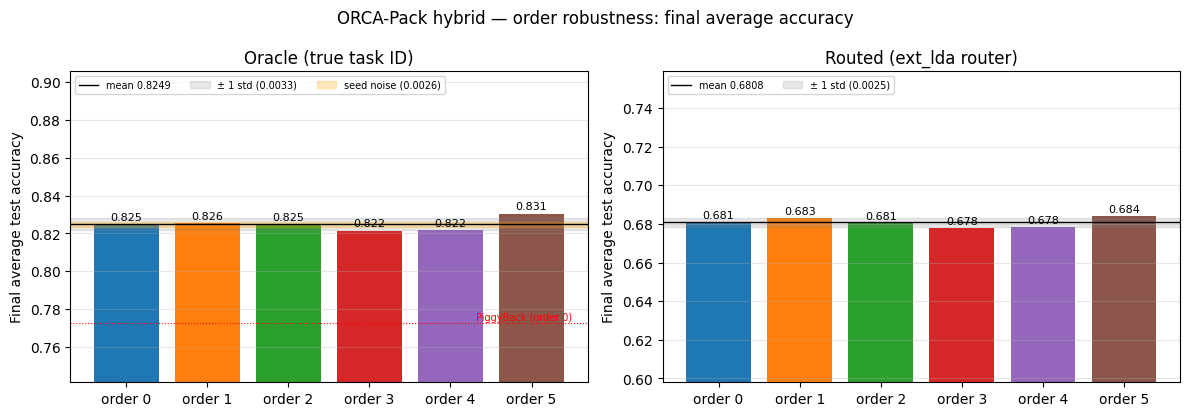

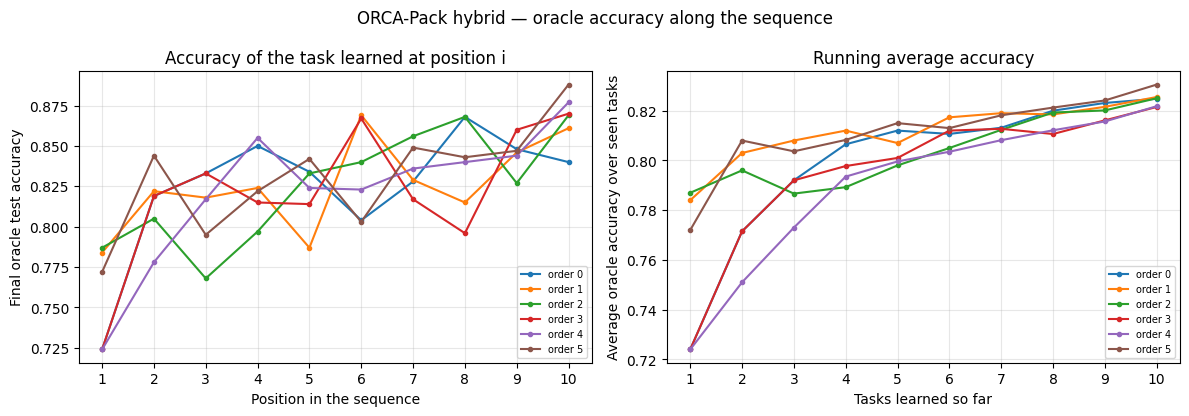

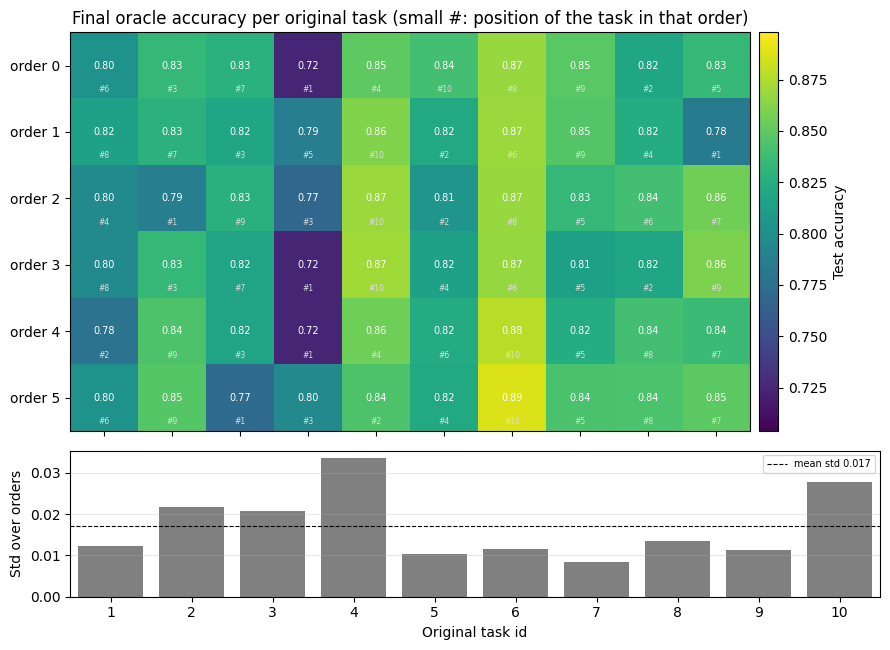

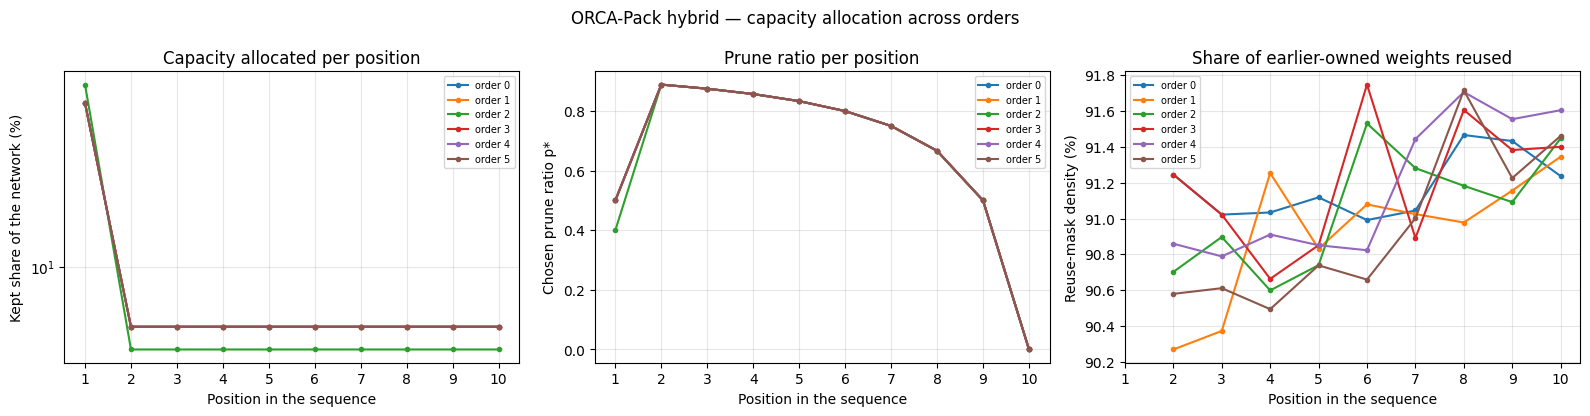

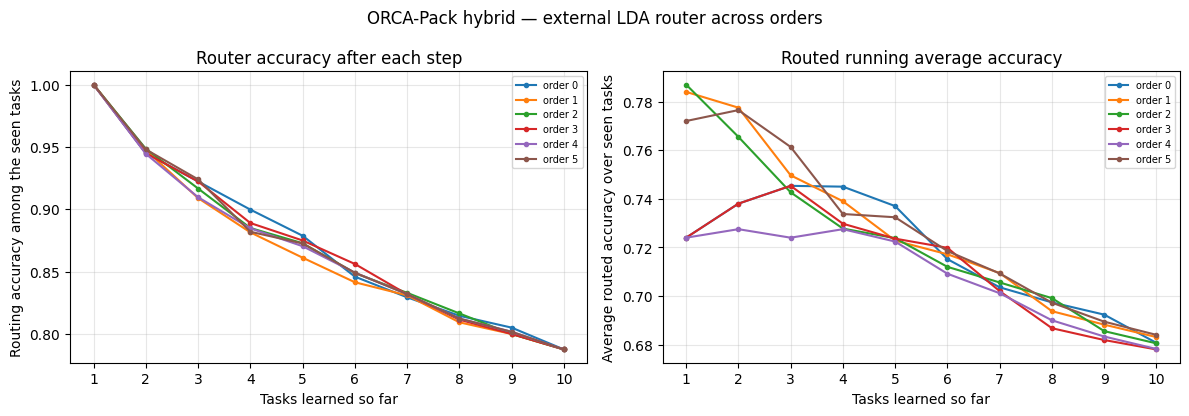

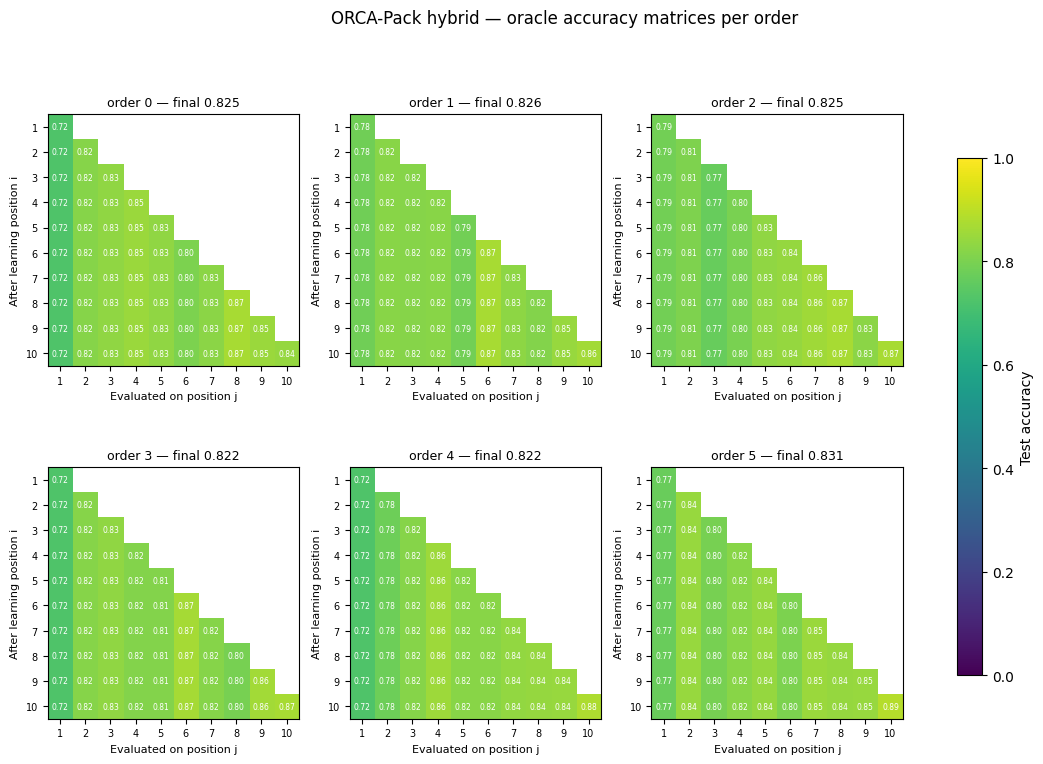

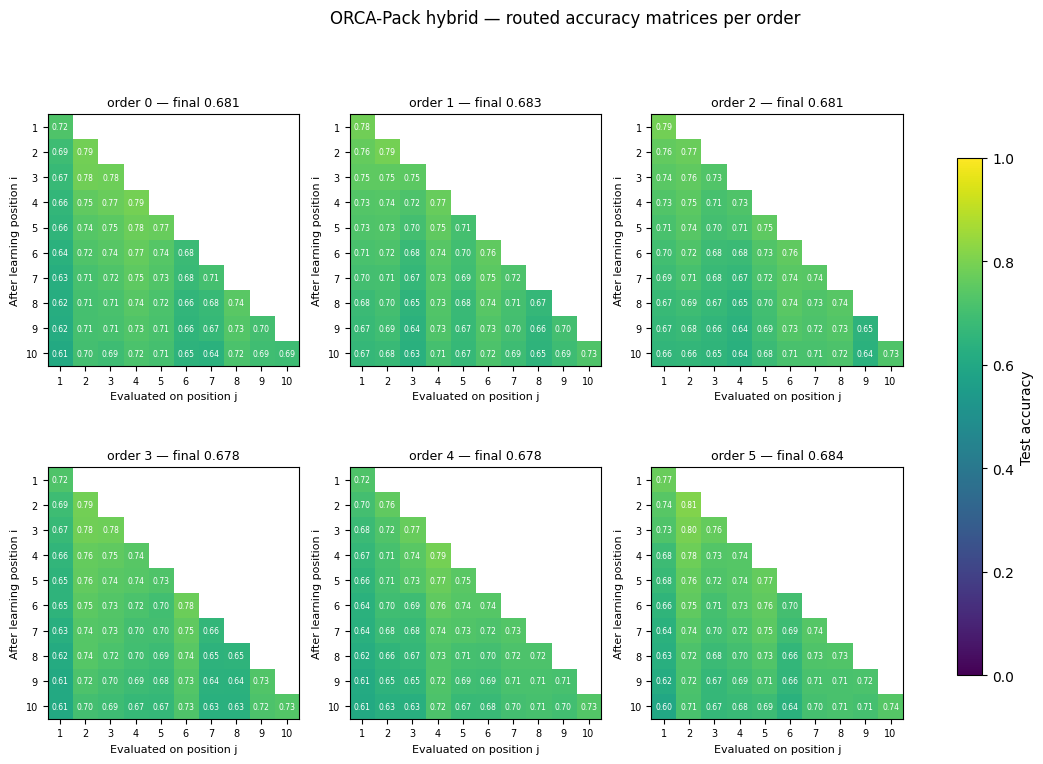

In [12]:
def _save(fig, name):
    fig.savefig(PLOT_DIR / f"orca_hybrid_orders_{name}.png", dpi=150, bbox_inches="tight")
    plt.show()

_cm = plt.get_cmap("tab10")
OCOL = {k: _cm(i % 10) for i, k in enumerate(ORDER_KEYS)}
_pos = np.arange(1, N_TASKS + 1)

def plot_final_accuracy():
    """Final average accuracy per order (oracle and routed) with mean, +- 1 std and the seed noise."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for ax, key, ttl in ((axes[0], "O", "Oracle (true task ID)"), (axes[1], "routed", "Routed (ext_lda router)")):
        v = np.array([RESULTS[k][key] for k in ORDER_KEYS])
        ax.bar(range(len(v)), v, color=[OCOL[k] for k in ORDER_KEYS])
        for i, x in enumerate(v):
            ax.text(i, x + 0.002, f"{x:.3f}", ha="center", fontsize=8)
        m, s = v.mean(), v.std(ddof=1) if len(v) > 1 else 0.0
        ax.axhline(m, color="k", lw=1, label=f"mean {m:.4f}")
        ax.axhspan(m - s, m + s, color="gray", alpha=0.18, label=f"± 1 std ({s:.4f})")
        if key == "O":
            ax.axhspan(m - SEED_NOISE_O / 2, m + SEED_NOISE_O / 2, color="orange", alpha=0.25, label=f"seed noise ({SEED_NOISE_O:.4f})")
            for n, x in REF_ORACLE.items():
                if x > v.min() - 0.06:
                    ax.axhline(x, color="r", ls=":", lw=0.8); ax.text(len(v) - 0.5, x, f"{n} (order 0)", fontsize=7, color="r", ha="right", va="bottom")
        ax.set_xticks(range(len(v))); ax.set_xticklabels([f"order {k}" for k in ORDER_KEYS])
        ax.set_ylim(max(0.0, v.min() - 0.08), v.max() + 0.075)
        ax.set_ylabel("Final average test accuracy"); ax.set_title(ttl); ax.grid(alpha=0.3, axis="y"); ax.legend(fontsize=7, loc="upper left", ncol=3)
    fig.suptitle("ORCA-Pack hybrid — order robustness: final average accuracy")
    fig.tight_layout()
    _save(fig, "final_accuracy")

def plot_position_curves():
    """Oracle accuracy per learning position, and the running average accuracy after each step."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for k in ORDER_KEYS:
        R = RESULTS[k]["R"]
        axes[0].plot(_pos, R[N_TASKS - 1], marker="o", ms=3, color=OCOL[k], label=f"order {k}")
        axes[1].plot(_pos, [np.nanmean(R[t, :t + 1]) for t in range(N_TASKS)], marker="o", ms=3, color=OCOL[k], label=f"order {k}")
    axes[0].set_xlabel("Position in the sequence"); axes[0].set_ylabel("Final oracle test accuracy"); axes[0].set_title("Accuracy of the task learned at position i")
    axes[1].set_xlabel("Tasks learned so far"); axes[1].set_ylabel("Average oracle accuracy over seen tasks"); axes[1].set_title("Running average accuracy")
    for ax in axes:
        ax.set_xticks(_pos); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    fig.suptitle("ORCA-Pack hybrid — oracle accuracy along the sequence")
    fig.tight_layout()
    _save(fig, "position_curves")

def plot_task_sensitivity():
    """Final oracle accuracy per ORIGINAL task id: which tasks depend on where they sit in the order."""
    fig, axes = plt.subplots(2, 1, figsize=(9, 6.6), gridspec_kw=dict(height_ratios=[len(ORDER_KEYS), 2.2]), sharex=True)
    im = axes[0].imshow(TASK_ACC, cmap="viridis", aspect="auto", vmin=np.nanmin(TASK_ACC) - 0.02, vmax=np.nanmax(TASK_ACC) + 0.01)
    axes[0].set_yticks(range(len(ORDER_KEYS))); axes[0].set_yticklabels([f"order {k}" for k in ORDER_KEYS])
    for i in range(TASK_ACC.shape[0]):
        for j in range(N_TASKS):
            axes[0].text(j, i, f"{TASK_ACC[i, j]:.2f}", ha="center", va="center", fontsize=7, color="w")
            axes[0].text(j, i + 0.36, f"#{RESULTS[ORDER_KEYS[i]]['order'].index(j) + 1}", ha="center", va="center", fontsize=5.5, color="#dddddd")
    fig.colorbar(im, ax=axes[0], label="Test accuracy", pad=0.01)
    axes[0].set_title("Final oracle accuracy per original task (small #: position of the task in that order)")
    sd = np.nanstd(TASK_ACC, axis=0, ddof=1) if len(ORDER_KEYS) > 1 else np.zeros(N_TASKS)
    axes[1].bar(range(N_TASKS), sd, color="gray")
    axes[1].axhline(sd.mean(), color="k", lw=0.8, ls="--", label=f"mean std {sd.mean():.3f}")
    axes[1].set_xticks(range(N_TASKS)); axes[1].set_xticklabels(range(1, N_TASKS + 1))
    axes[1].set_xlabel("Original task id"); axes[1].set_ylabel("Std over orders"); axes[1].grid(alpha=0.3, axis="y"); axes[1].legend(fontsize=7)
    fig.tight_layout()
    _save(fig, "task_sensitivity")

def plot_capacity_orders():
    """Capacity allocation: kept share per position, prune ratio p* per position and the reuse-mask density per position."""
    fig, axes = plt.subplots(1, 3, figsize=(16, 4.2))
    for k in ORDER_KEYS:
        r = RESULTS[k]
        axes[0].plot(_pos, np.array(r["capacity_per_task"]) * 100, marker="o", ms=3, color=OCOL[k], label=f"order {k}")
        axes[1].plot(_pos, r["p_star"], marker="o", ms=3, color=OCOL[k], label=f"order {k}")
    axes[0].set_yscale("symlog", linthresh=1.0); axes[0].set_ylabel("Kept share of the network (%)"); axes[0].set_title("Capacity allocated per position")
    axes[1].set_ylabel("Chosen prune ratio p*"); axes[1].set_title("Prune ratio per position")
    for ax in axes[:2]:
        ax.set_xlabel("Position in the sequence"); ax.set_xticks(_pos); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    for k in ORDER_KEYS:
        dens = np.array([np.nan if d is None else d * 100 for d in RESULTS[k]["mask_density"]], dtype=float)
        axes[2].plot(_pos, dens, marker="o", ms=3, color=OCOL[k], label=f"order {k}")
    axes[2].set_xlabel("Position in the sequence"); axes[2].set_xticks(_pos); axes[2].set_ylabel("Reuse-mask density (%)")
    axes[2].set_title("Share of earlier-owned weights reused"); axes[2].grid(alpha=0.3); axes[2].legend(fontsize=7)
    fig.suptitle("ORCA-Pack hybrid — capacity allocation across orders")
    fig.tight_layout()
    _save(fig, "capacity")

def plot_routing_orders():
    """Routing accuracy after each step and the routed average accuracy after each step."""
    fig, axes = plt.subplots(1, 2, figsize=(12, 4.2))
    for k in ORDER_KEYS:
        r = RESULTS[k]
        axes[0].plot(_pos, r["routing_by_step"], marker="o", ms=3, color=OCOL[k], label=f"order {k}")
        axes[1].plot(_pos, [np.nanmean(r["R_routed"][t, :t + 1]) for t in range(N_TASKS)], marker="o", ms=3, color=OCOL[k], label=f"order {k}")
    axes[0].set_ylabel("Routing accuracy among the seen tasks"); axes[0].set_title("Router accuracy after each step")
    axes[1].set_ylabel("Average routed accuracy over seen tasks"); axes[1].set_title("Routed running average accuracy")
    for ax in axes:
        ax.set_xlabel("Tasks learned so far"); ax.set_xticks(_pos); ax.grid(alpha=0.3); ax.legend(fontsize=7)
    fig.suptitle("ORCA-Pack hybrid — external LDA router across orders")
    fig.tight_layout()
    _save(fig, "routing")

def plot_matrices_orders(key, name, title):
    n = len(ORDER_KEYS); n_cols = min(3, n); n_rows = math.ceil(n / n_cols)
    fig, axes = plt.subplots(n_rows, n_cols, figsize=(4.6 * n_cols, 4.2 * n_rows), squeeze=False)
    for ax, k in zip(axes.flat, ORDER_KEYS):
        mat = RESULTS[k][key]
        im = ax.imshow(mat, vmin=0, vmax=1, cmap="viridis")
        ax.set_xticks(range(N_TASKS)); ax.set_yticks(range(N_TASKS))
        ax.set_xticklabels(_pos, fontsize=7); ax.set_yticklabels(_pos, fontsize=7)
        ax.set_xlabel("Evaluated on position j", fontsize=8); ax.set_ylabel("After learning position i", fontsize=8)
        for i in range(N_TASKS):
            for j in range(N_TASKS):
                if not np.isnan(mat[i, j]):
                    ax.text(j, i, f"{mat[i, j]:.2f}", ha="center", va="center", fontsize=5.5, color="w")
        ax.set_title(f"order {k} — final {np.nanmean(mat[N_TASKS - 1]):.3f}", fontsize=9)
    for ax in list(axes.flat)[n:]:
        ax.axis("off")
    fig.colorbar(im, ax=axes, label="Test accuracy", shrink=0.8)
    fig.suptitle(title)
    _save(fig, name)

plot_final_accuracy()
plot_position_curves()
plot_task_sensitivity()
plot_capacity_orders()
plot_routing_orders()
plot_matrices_orders("R", "matrices_oracle", "ORCA-Pack hybrid — oracle accuracy matrices per order")
plot_matrices_orders("R_routed", "matrices_routed", "ORCA-Pack hybrid — routed accuracy matrices per order")

## Results to keep

In [13]:
ORDER_ROBUSTNESS = dict(
    config=dict(a=FINAL_A, mode=FINAL_MODE, seed=SEED, router="C: ext_lda", reuse_mask=True, mask_lr=MASK_LR),
    orders={k: dict(order=r["order"], oracle=r["O"], routed=r["routed"], routing_T10=r["routing_by_step"][-1], unused=r["unused"],
                    per_position_oracle=np.diag(r["R"]).tolist(), per_position_routed=np.diag(r["R_routed"]).tolist(),
                    kept_share=r["capacity_per_task"], train_min=r["train_min"]) for k, r in RESULTS.items()},
    oracle=_stats(metrics["oracle"]), routed=_stats(metrics["routed"]), seed_noise_O=SEED_NOISE_O)
print("ORDER_ROBUSTNESS =", json.dumps(to_jsonable(ORDER_ROBUSTNESS)))
print(f"\nfull records of every order: {RESULTS_JSON}")
print(f"total notebook time: {(time.time() - T_START) / 60:.1f} min")

ORDER_ROBUSTNESS = {"config": {"a": 0.7, "mode": "floor", "seed": 67, "router": "C: ext_lda", "reuse_mask": true, "mask_lr": 0.0003}, "orders": {"0": {"order": [3, 8, 1, 4, 9, 0, 2, 6, 7, 5], "oracle": 0.824800044298172, "routed": 0.6807000279426575, "routing_T10": 0.7876, "unused": 0.0, "per_position_oracle": [0.7240000367164612, 0.8190000653266907, 0.8330000638961792, 0.8500000238418579, 0.8340000510215759, 0.8040000200271606, 0.8280000686645508, 0.8680000305175781, 0.8480000495910645, 0.8400000333786011], "per_position_routed": [0.7240000367164612, 0.7870000600814819, 0.7790000438690186, 0.7910000085830688, 0.7660000324249268, 0.6820000410079956, 0.7070000171661377, 0.7440000176429749, 0.7000000476837158, 0.6890000104904175], "kept_share": [0.5, 0.05555569767219762, 0.05555569767219762, 0.05555527132227143, 0.05555514341729357, 0.05555578294218286, 0.055555655037205, 0.055555655037205, 0.05555544186224191, 0.055555655037205], "train_min": 24.416451573371887}, "1": {"order": [9, 5, 2